In [1]:
# import numpy and pandas libraries

import pandas as pd
import numpy as np

# load the dataset

df = pd.read_excel('P706_ World_development_mesurement.xlsx')

# show the first 5 records in dataset

df.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Country,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,0.020,NaN,87931.0,Algeria,NaN,NaN,26998.0,"$54,790,058,957",0.035,$60,...,67.0,0.0,1,0.342,0.619,0.039,31719449,0.599,"$102,000,000","$193,000,000"
1,0.050,NaN,9542.0,Angola,NaN,NaN,7499.0,"$9,129,594,819",0.034,$22,...,44.0,0.0,1,0.476,0.499,0.025,13924930,0.324,"$34,000,000","$146,000,000"
2,0.043,NaN,1617.0,Benin,NaN,NaN,1983.0,"$2,359,122,303",0.043,$15,...,53.0,0.0,1,0.454,0.517,0.029,6949366,0.383,"$77,000,000","$50,000,000"
3,0.027,NaN,4276.0,Botswana,NaN,NaN,1836.0,"$5,788,311,645",0.047,$152,...,49.0,0.1,1,0.383,0.587,0.029,1755375,0.532,"$227,000,000","$209,000,000"
4,0.046,NaN,1041.0,Burkina Faso,NaN,NaN,NaN,"$2,610,959,139",0.051,$12,...,49.0,0.0,1,0.468,0.505,0.028,11607944,0.178,"$23,000,000","$30,000,000"


In [2]:
# find the shape of the dataset

df.shape

(2704, 25)

In [3]:
# check the datatypes of the columns

df.dtypes

Birth Rate                float64
Business Tax Rate             str
CO2 Emissions             float64
Country                       str
Days to Start Business    float64
Ease of Business          float64
Energy Usage              float64
GDP                           str
Health Exp % GDP          float64
Health Exp/Capita             str
Hours to do Tax           float64
Infant Mortality Rate     float64
Internet Usage            float64
Lending Interest          float64
Life Expectancy Female    float64
Life Expectancy Male      float64
Mobile Phone Usage        float64
Number of Records           int64
Population 0-14           float64
Population 15-64          float64
Population 65+            float64
Population Total            int64
Population Urban          float64
Tourism Inbound               str
Tourism Outbound              str
dtype: object

In [4]:
# dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   str    
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   str    
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   str    
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   str    
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   float64
 15

In [5]:
# check the missing values

df.isnull().sum()

Birth Rate                 119
Business Tax Rate         1281
CO2 Emissions              579
Country                      0
Days to Start Business     986
Ease of Business          2519
Energy Usage               919
GDP                        210
Health Exp % GDP           309
Health Exp/Capita          309
Hours to do Tax           1288
Infant Mortality Rate      260
Internet Usage             173
Lending Interest           824
Life Expectancy Female     136
Life Expectancy Male       136
Mobile Phone Usage         167
Number of Records            0
Population 0-14            220
Population 15-64           220
Population 65+             220
Population Total             0
Population Urban            26
Tourism Inbound            368
Tourism Outbound           471
dtype: int64

In [6]:
# check the duplicate records

df.duplicated().sum()

np.int64(0)

In [7]:
# Percentage of missing values

missing_percent = (df.isnull().sum() / len(df))*100

missing_percent

Birth Rate                 4.400888
Business Tax Rate         47.374260
CO2 Emissions             21.412722
Country                    0.000000
Days to Start Business    36.464497
Ease of Business          93.158284
Energy Usage              33.986686
GDP                        7.766272
Health Exp % GDP          11.427515
Health Exp/Capita         11.427515
Hours to do Tax           47.633136
Infant Mortality Rate      9.615385
Internet Usage             6.397929
Lending Interest          30.473373
Life Expectancy Female     5.029586
Life Expectancy Male       5.029586
Mobile Phone Usage         6.176036
Number of Records          0.000000
Population 0-14            8.136095
Population 15-64           8.136095
Population 65+             8.136095
Population Total           0.000000
Population Urban           0.961538
Tourism Inbound           13.609467
Tourism Outbound          17.418639
dtype: float64

In [8]:
# create a dataframe of missing values and missing percentage

missing_df = pd.DataFrame({
    'Missing_count':df.isnull().sum(),
    'Missing Percentage':missing_percent
})

# sort the dataframe values

missing_df = missing_df.sort_values(by = 'Missing Percentage',ascending = False)


missing_df

,Missing_count,Missing Percentage
Ease of Business,2519,93.158284
Hours to do Tax,1288,47.633136
Business Tax Rate,1281,47.374260
Days to Start Business,986,36.464497
Energy Usage,919,33.986686
Lending Interest,824,30.473373
CO2 Emissions,579,21.412722
Tourism Outbound,471,17.418639
Tourism Inbound,368,13.609467
Health Exp/Capita,309,11.427515


In [9]:
# Drop columns having more than 50% missing values

threshold = 50

cols_to_drop = missing_percent[missing_percent > threshold].index

df.drop(columns = cols_to_drop,inplace = True)

print('Dropped columns:',list(cols_to_drop))

Dropped columns: ['Ease of Business']


In [10]:
# after remove the column check dataset shape

df.shape

(2704, 24)

In [11]:
df['Business Tax Rate'].value_counts()

Business Tax Rate
44.1%     20
37.5%     14
36.3%     13
35.0%     13
34.0%     12
          ..
107.8%     1
68.5%      1
76.0%      1
40.5%      1
50.7%      1
Name: count, Length: 447, dtype: int64

In [12]:
cat_cols = ['Business Tax Rate','GDP','Health Exp/Capita','Tourism Inbound','Tourism Outbound']

In [13]:
cat_cols

['Business Tax Rate',
 'GDP',
 'Health Exp/Capita',
 'Tourism Inbound',
 'Tourism Outbound']

In [14]:
# Data Cleaning

for col in cat_cols:
    df[col] = (
        df[col]
        .str.replace('%','',regex = False)
        .str.replace('$','',regex = False)
        .str.replace(',','',regex = False)
    )

In [15]:
# convert object datatype to numeric datatype


for col in cat_cols:
    df[col] = pd.to_numeric(df[col],errors = 'coerce')

In [16]:
# check datatypes

df.dtypes

Birth Rate                float64
Business Tax Rate         float64
CO2 Emissions             float64
Country                       str
Days to Start Business    float64
Energy Usage              float64
GDP                       float64
Health Exp % GDP          float64
Health Exp/Capita         float64
Hours to do Tax           float64
Infant Mortality Rate     float64
Internet Usage            float64
Lending Interest          float64
Life Expectancy Female    float64
Life Expectancy Male      float64
Mobile Phone Usage        float64
Number of Records           int64
Population 0-14           float64
Population 15-64          float64
Population 65+            float64
Population Total            int64
Population Urban          float64
Tourism Inbound           float64
Tourism Outbound          float64
dtype: object

In [17]:
df.isnull().sum()

Birth Rate                 119
Business Tax Rate         1281
CO2 Emissions              579
Country                      0
Days to Start Business     986
Energy Usage               919
GDP                        210
Health Exp % GDP           309
Health Exp/Capita          309
Hours to do Tax           1288
Infant Mortality Rate      260
Internet Usage             173
Lending Interest           824
Life Expectancy Female     136
Life Expectancy Male       136
Mobile Phone Usage         167
Number of Records            0
Population 0-14            220
Population 15-64           220
Population 65+             220
Population Total             0
Population Urban            26
Tourism Inbound            368
Tourism Outbound           471
dtype: int64

In [18]:
df.describe()

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
count,2585.000000,1423.000000,2.125000e+03,1718.000000,1.785000e+03,2.494000e+03,2395.000000,2395.000000,1416.000000,2444.000000,...,2568.000000,2537.000000,2704.0,2484.000000,2484.000000,2484.000000,2.704000e+03,2678.000000,2.336000e+03,2.233000e+03
mean,0.022715,48.966901,1.423071e+05,39.999418,7.723684e+04,2.638540e+11,0.064170,801.397077,302.068503,0.032813,...,66.461838,0.578124,1.0,0.303051,0.623481,0.073465,3.145729e+07,0.562953,4.939320e+09,4.729435e+09
std,0.011338,40.954116,6.159288e+05,57.318588,2.599239e+05,1.129910e+12,0.026325,1473.448036,273.299686,0.029968,...,9.390217,0.474647,0.0,0.106577,0.069660,0.049541,1.242894e+08,0.245897,1.385098e+10,1.326774e+10
min,0.007000,8.200000,7.000000e+00,1.000000,8.000000e+00,6.310127e+07,0.008000,2.000000,12.000000,0.002000,...,37.000000,0.000000,1.0,0.118000,0.474000,0.003000,1.887600e+04,0.082000,7.000000e+05,2.000000e+05
25%,0.013000,32.400000,1.360000e+03,13.000000,3.737000e+03,3.539042e+09,0.046000,50.000000,156.000000,0.009000,...,61.000000,0.100000,1.0,0.204750,0.559000,0.033000,8.783360e+05,0.356000,1.250000e+08,1.100000e+08
50%,0.020000,41.000000,8.529000e+03,26.000000,1.433800e+04,1.507975e+10,0.061000,193.000000,239.000000,0.020000,...,69.000000,0.500000,1.0,0.299500,0.642500,0.052000,5.800324e+06,0.560000,6.885000e+08,4.560000e+08
75%,0.031000,51.550000,5.910800e+04,45.000000,4.185200e+04,1.102047e+11,0.079000,665.000000,344.750000,0.053000,...,73.250000,0.900000,1.0,0.402000,0.676000,0.112000,2.014089e+07,0.765000,3.601500e+09,2.842000e+09
max,0.053000,339.100000,8.286892e+06,694.000000,2.727728e+06,1.624460e+13,0.225000,9908.000000,2600.000000,0.141000,...,88.000000,2.900000,1.0,0.500000,0.858000,0.244000,1.350695e+09,1.000000,2.000920e+11,1.265730e+11


In [19]:
num_cols = df.select_dtypes(include = ['int64','float64']).columns
cat_cols = df.select_dtypes(include = ['str']).columns

In [20]:
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [21]:
df.isnull().sum()

Birth Rate                0
Business Tax Rate         0
CO2 Emissions             0
Country                   0
Days to Start Business    0
Energy Usage              0
GDP                       0
Health Exp % GDP          0
Health Exp/Capita         0
Hours to do Tax           0
Infant Mortality Rate     0
Internet Usage            0
Lending Interest          0
Life Expectancy Female    0
Life Expectancy Male      0
Mobile Phone Usage        0
Number of Records         0
Population 0-14           0
Population 15-64          0
Population 65+            0
Population Total          0
Population Urban          0
Tourism Inbound           0
Tourism Outbound          0
dtype: int64

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

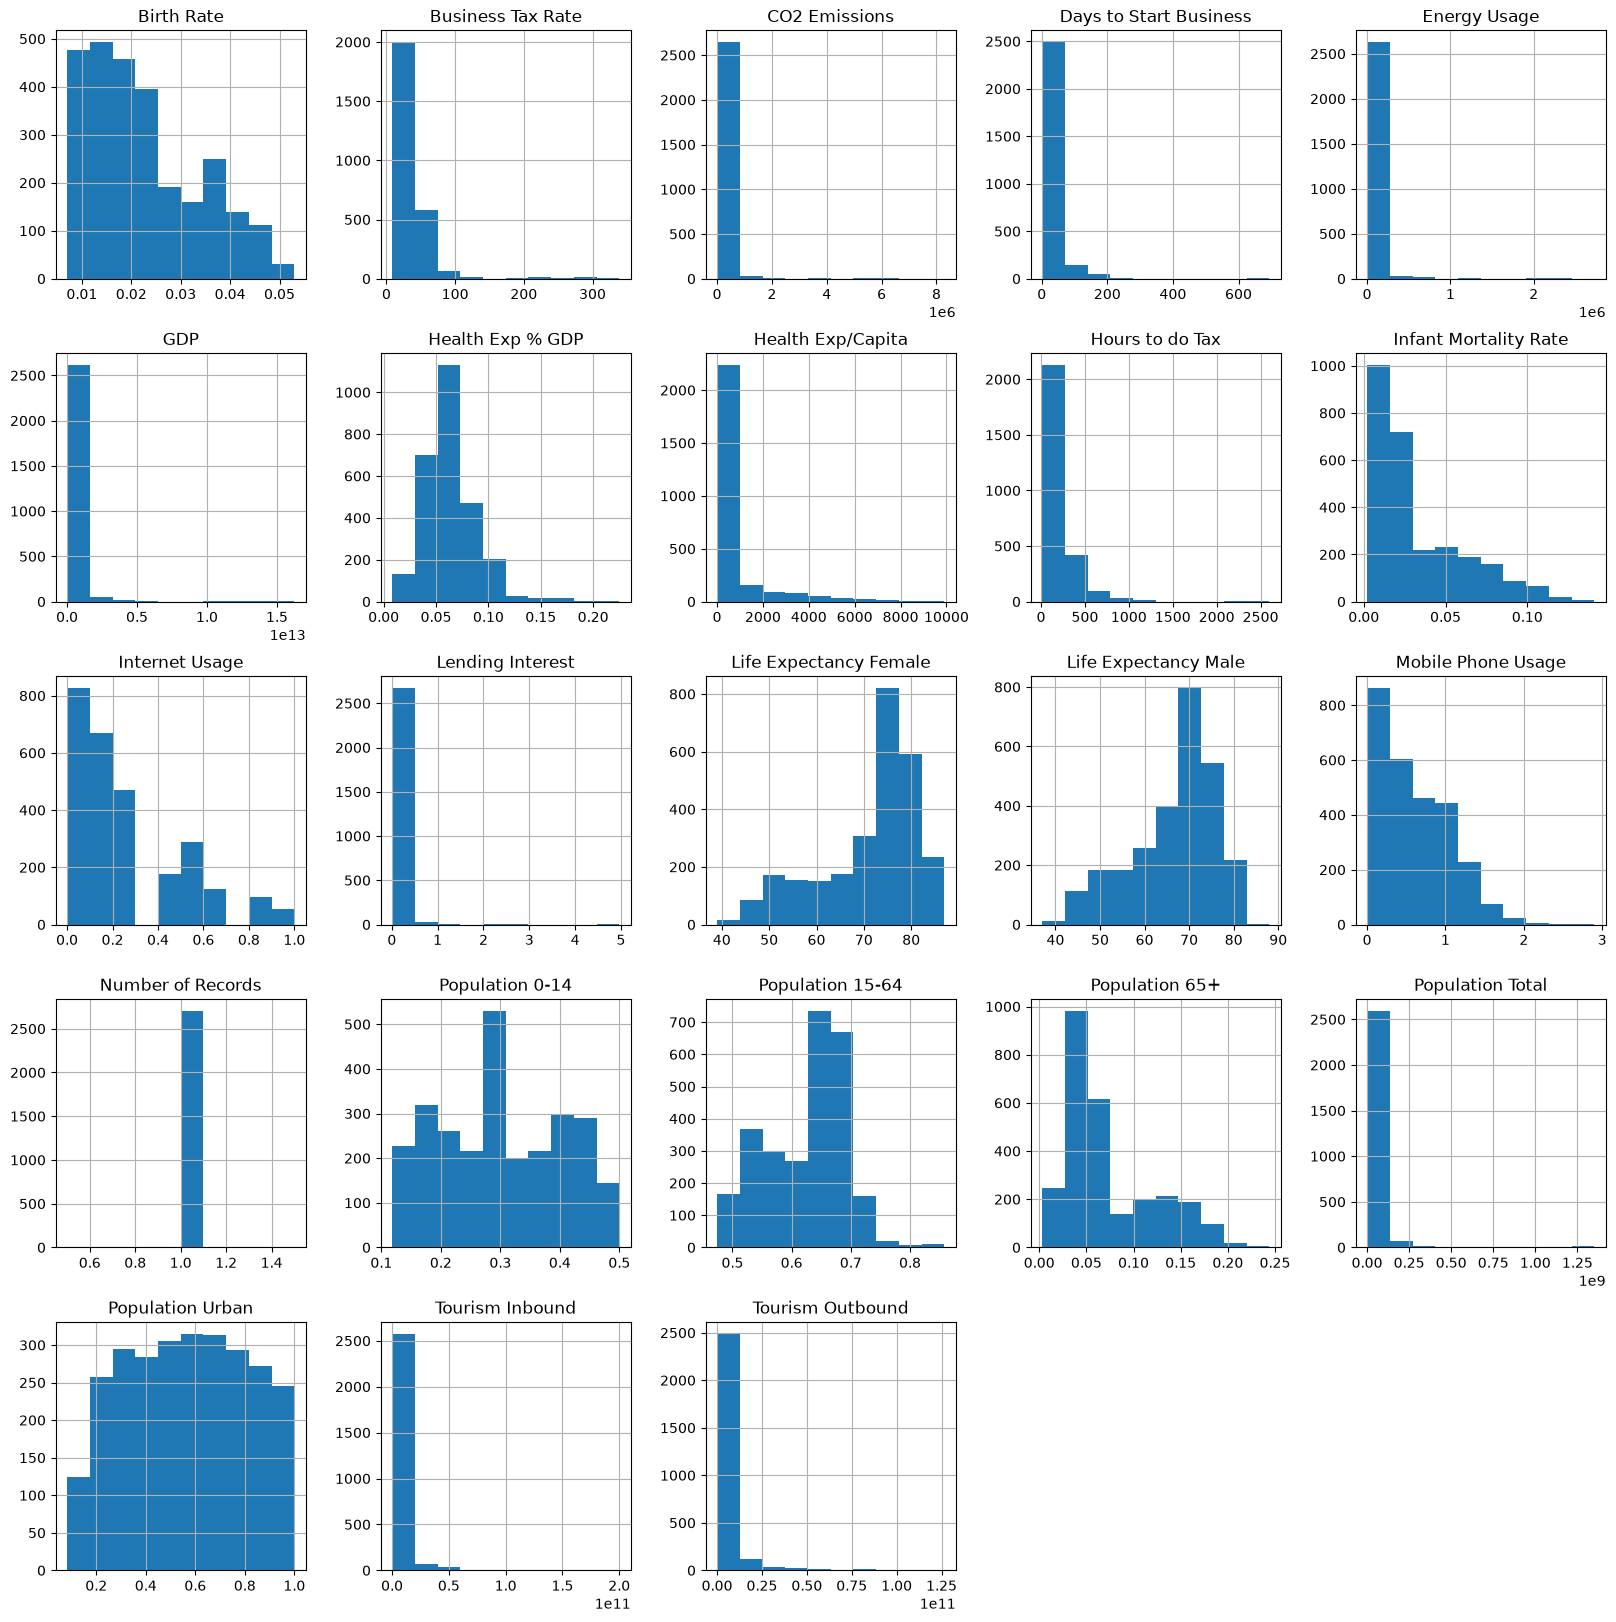

In [24]:
df.hist(figsize = (20,20))
plt.show()

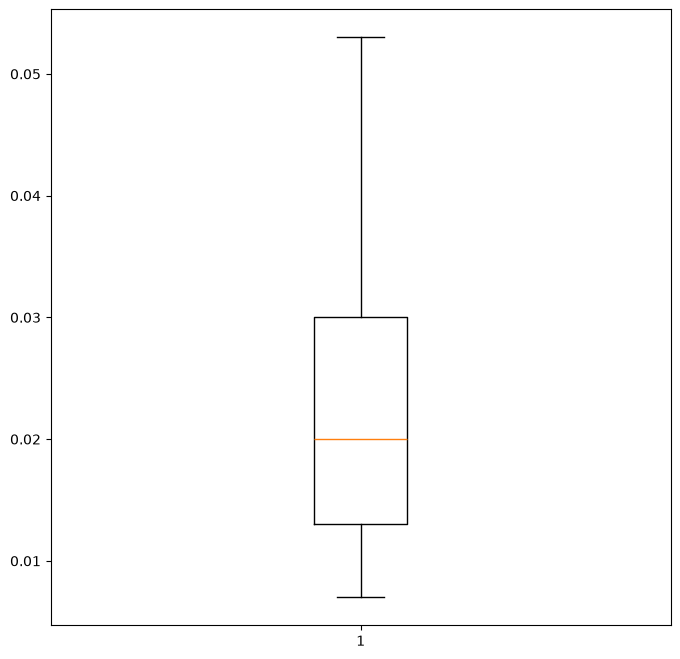

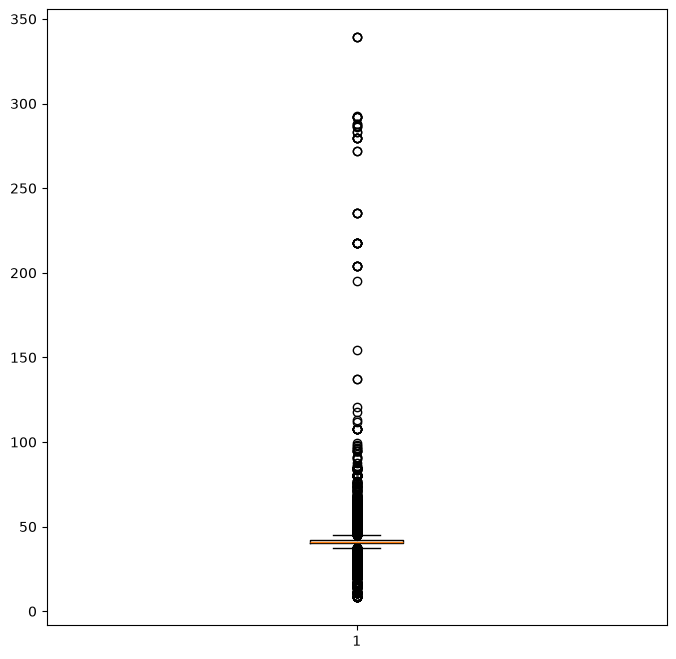

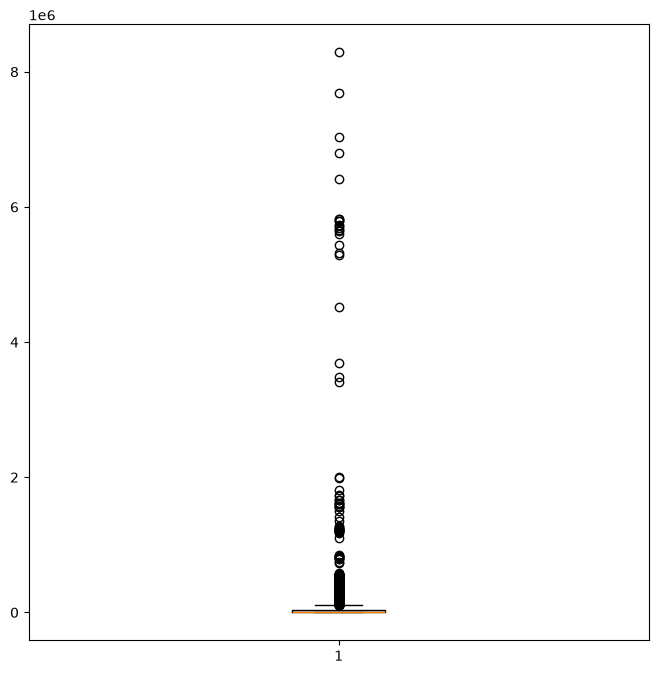

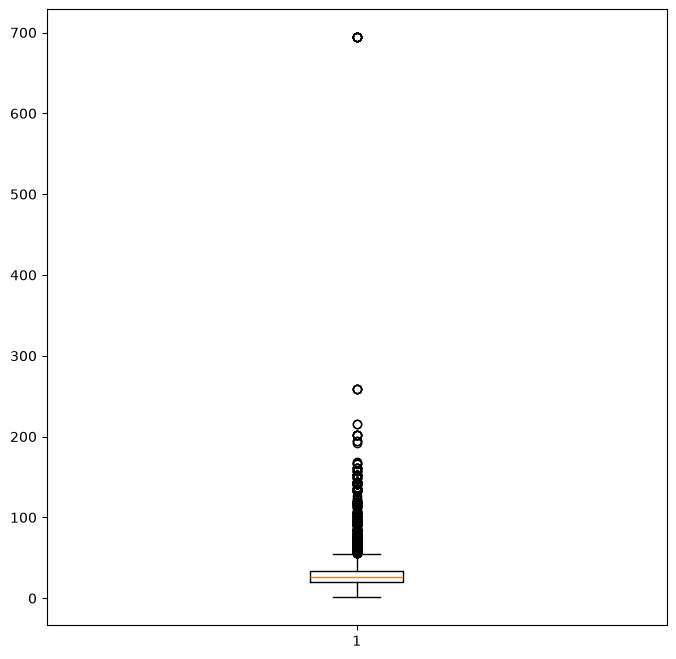

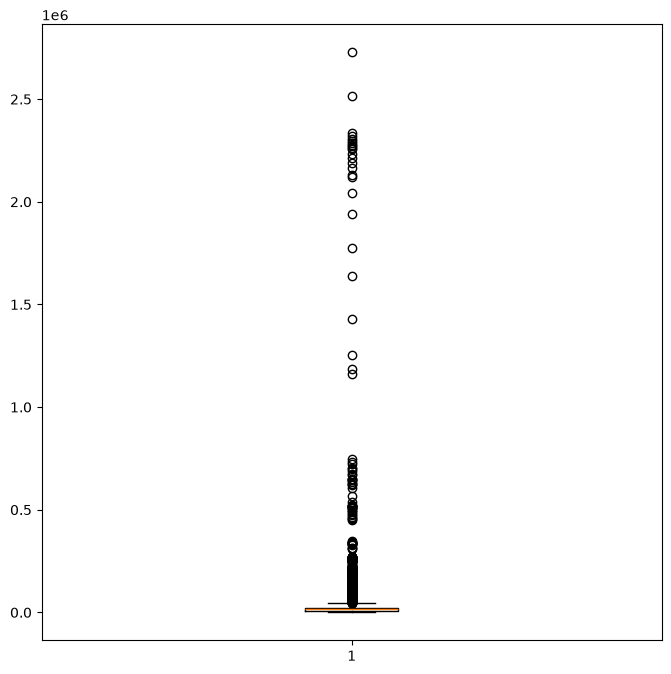

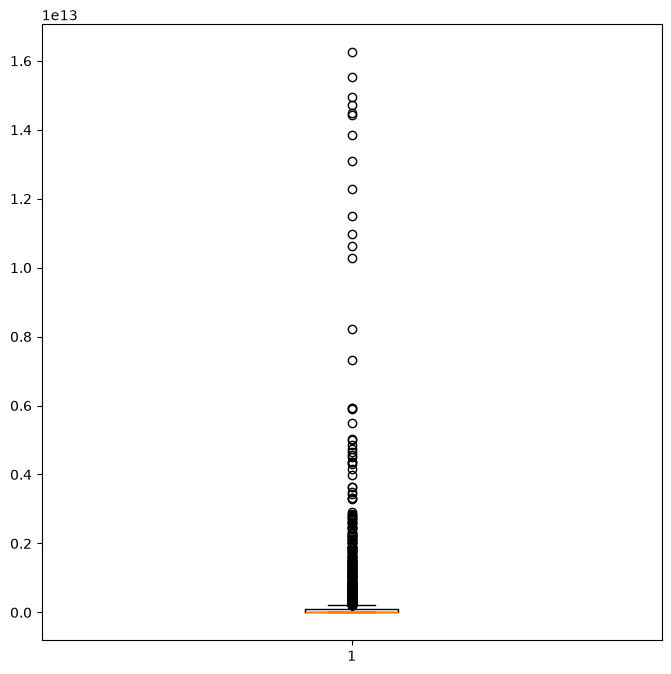

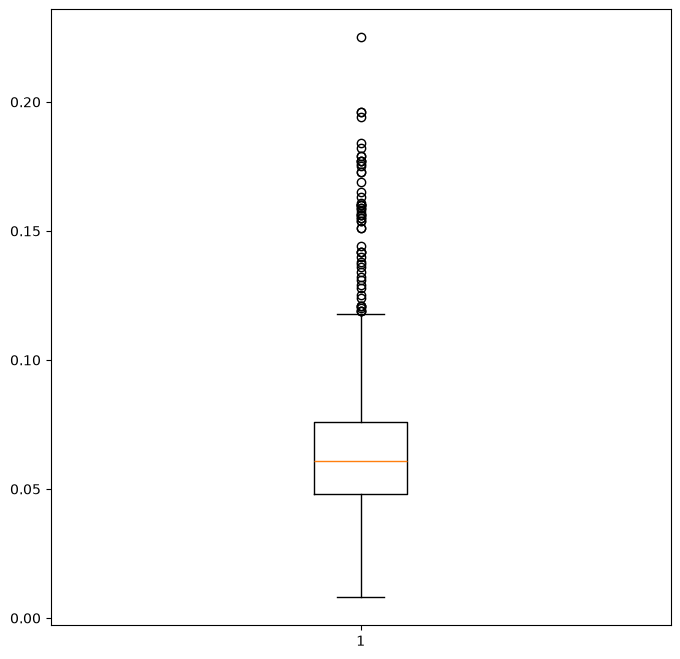

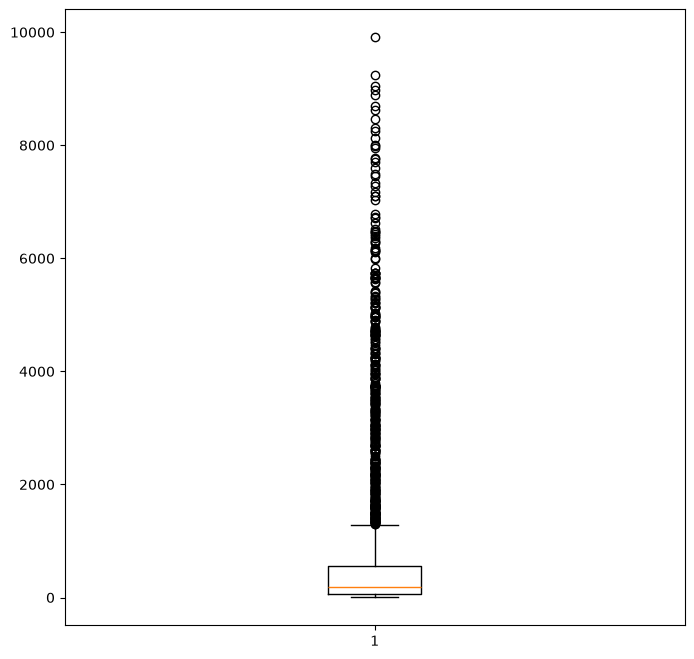

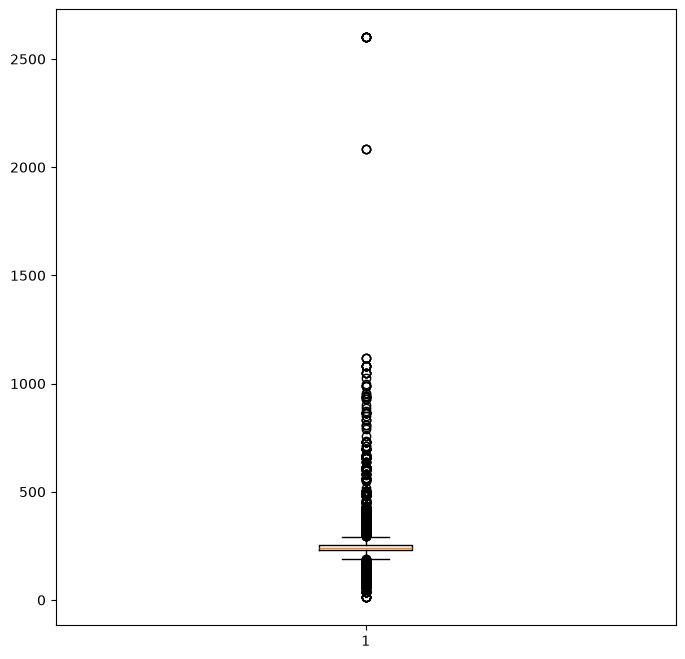

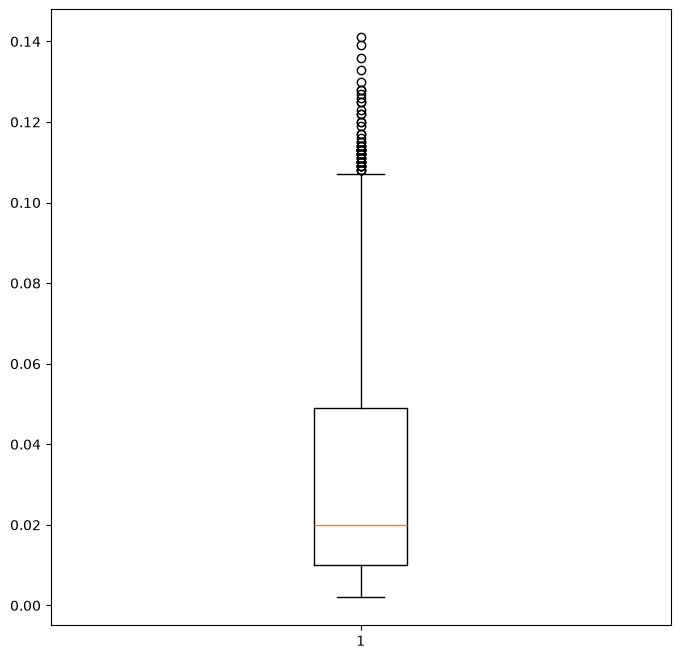

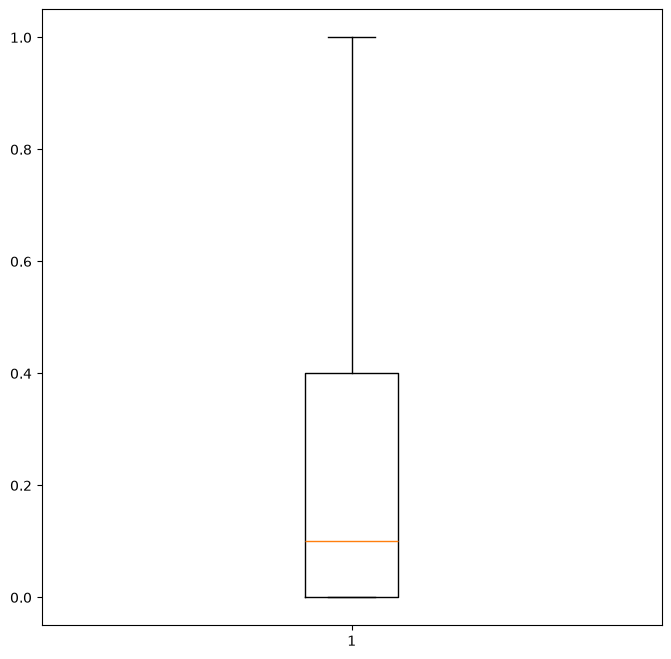

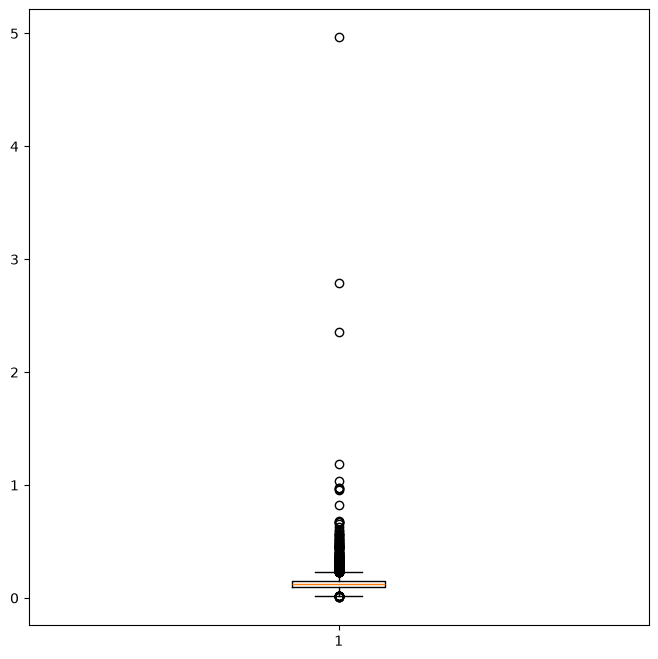

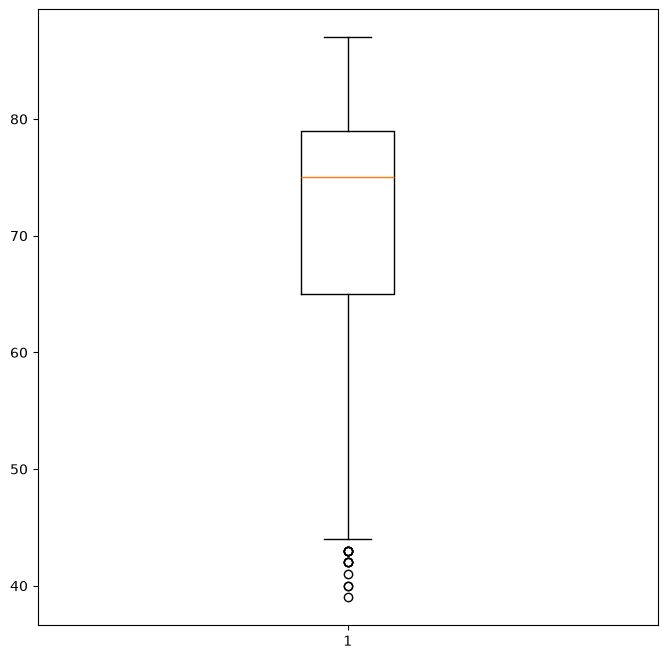

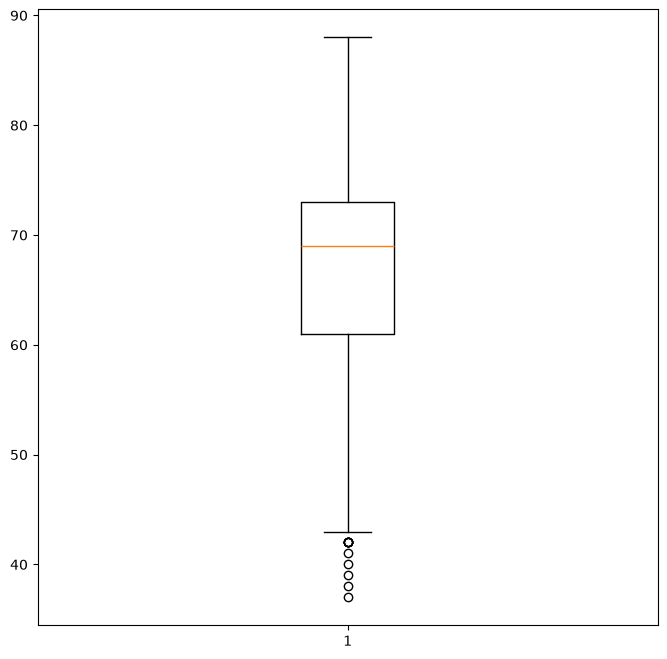

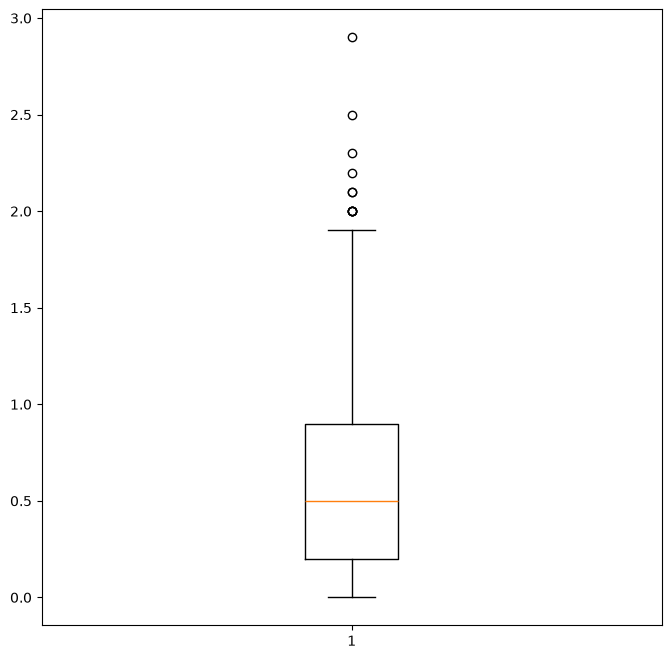

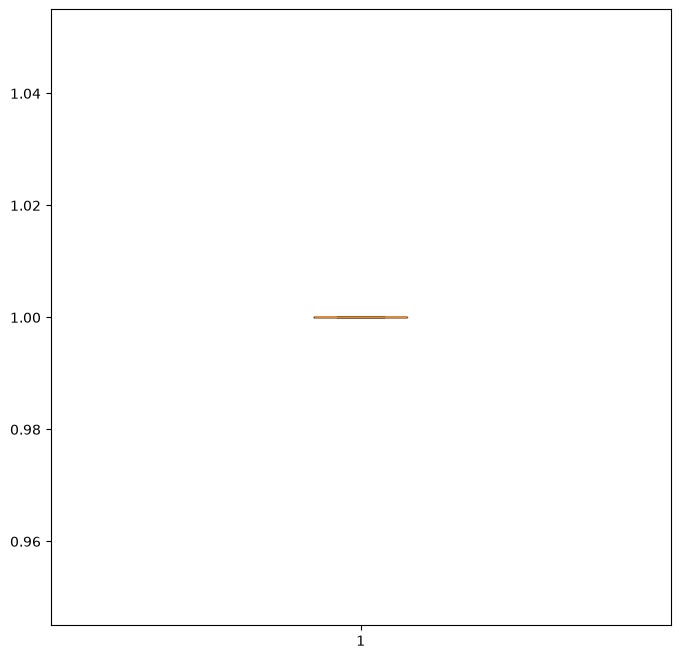

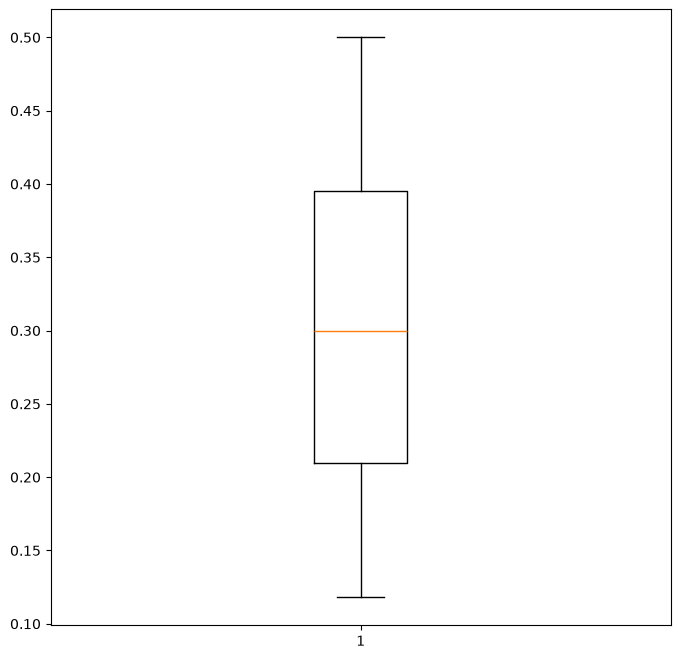

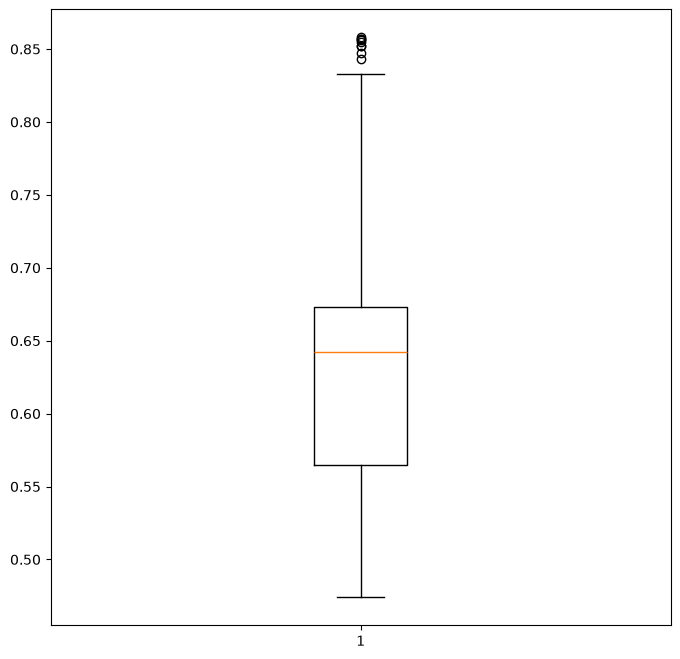

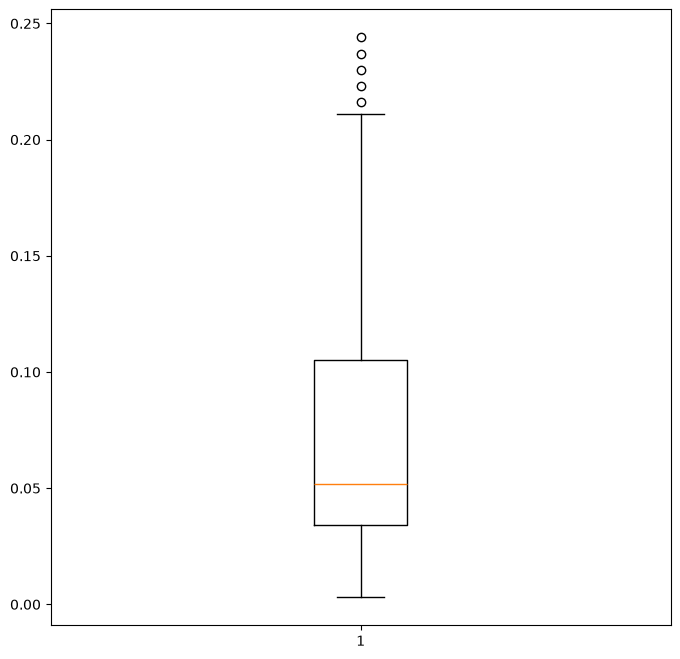

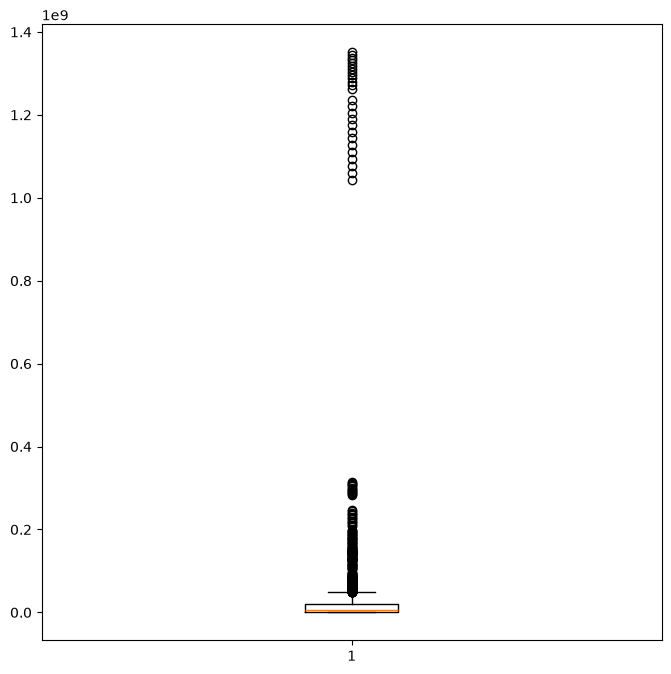

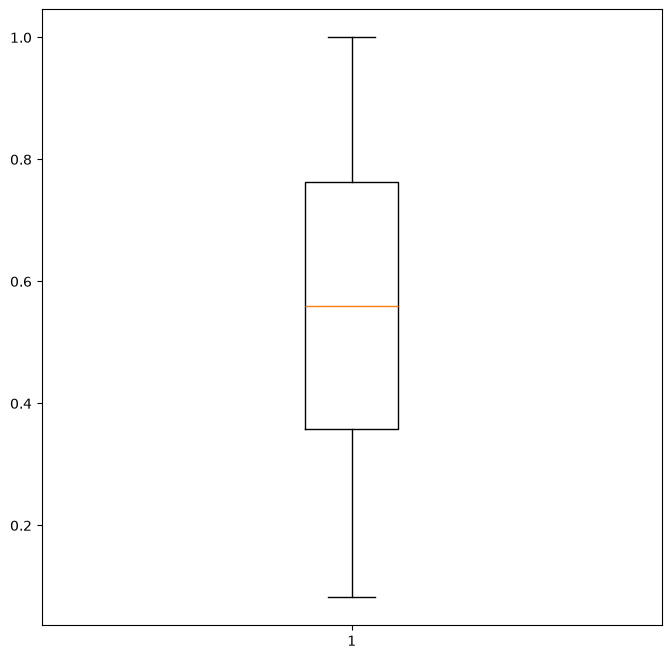

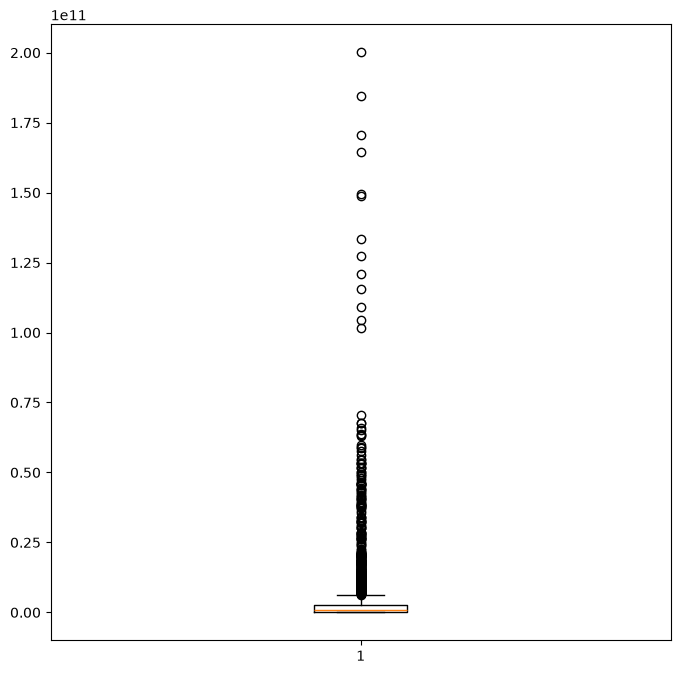

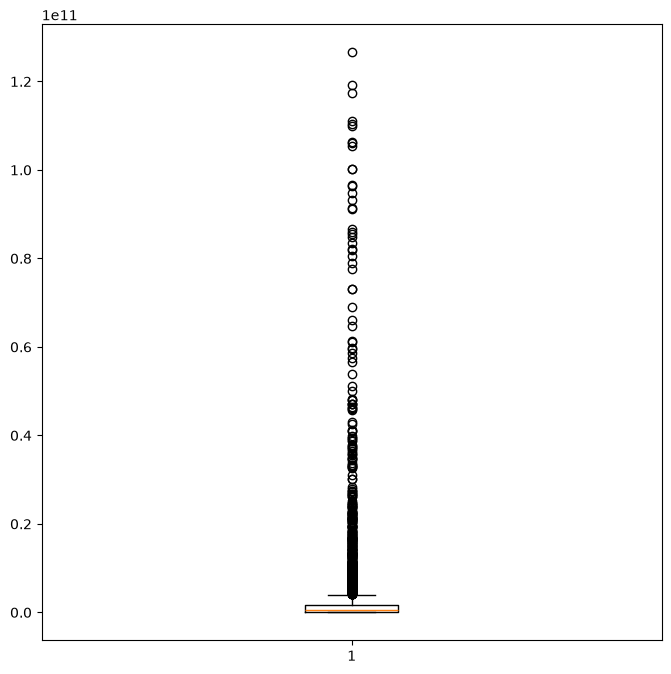

In [25]:
for col in num_cols:
    plt.figure(figsize = (8,8))
    plt.boxplot(df[col])
    plt.show()

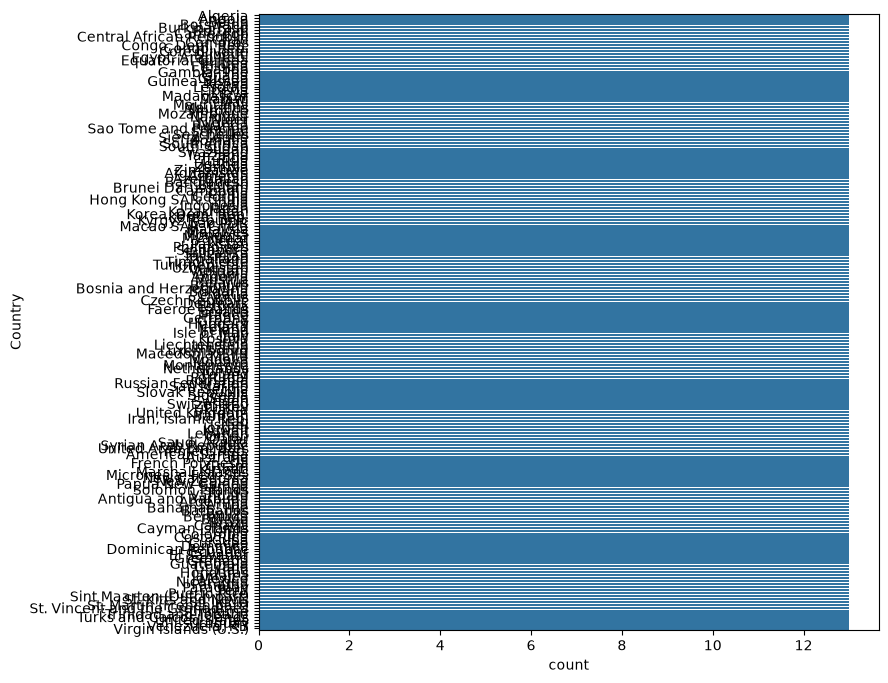

In [26]:
for col in cat_cols:
    plt.figure(figsize = (8,8))
    sns.countplot(df[col])
    plt.show()

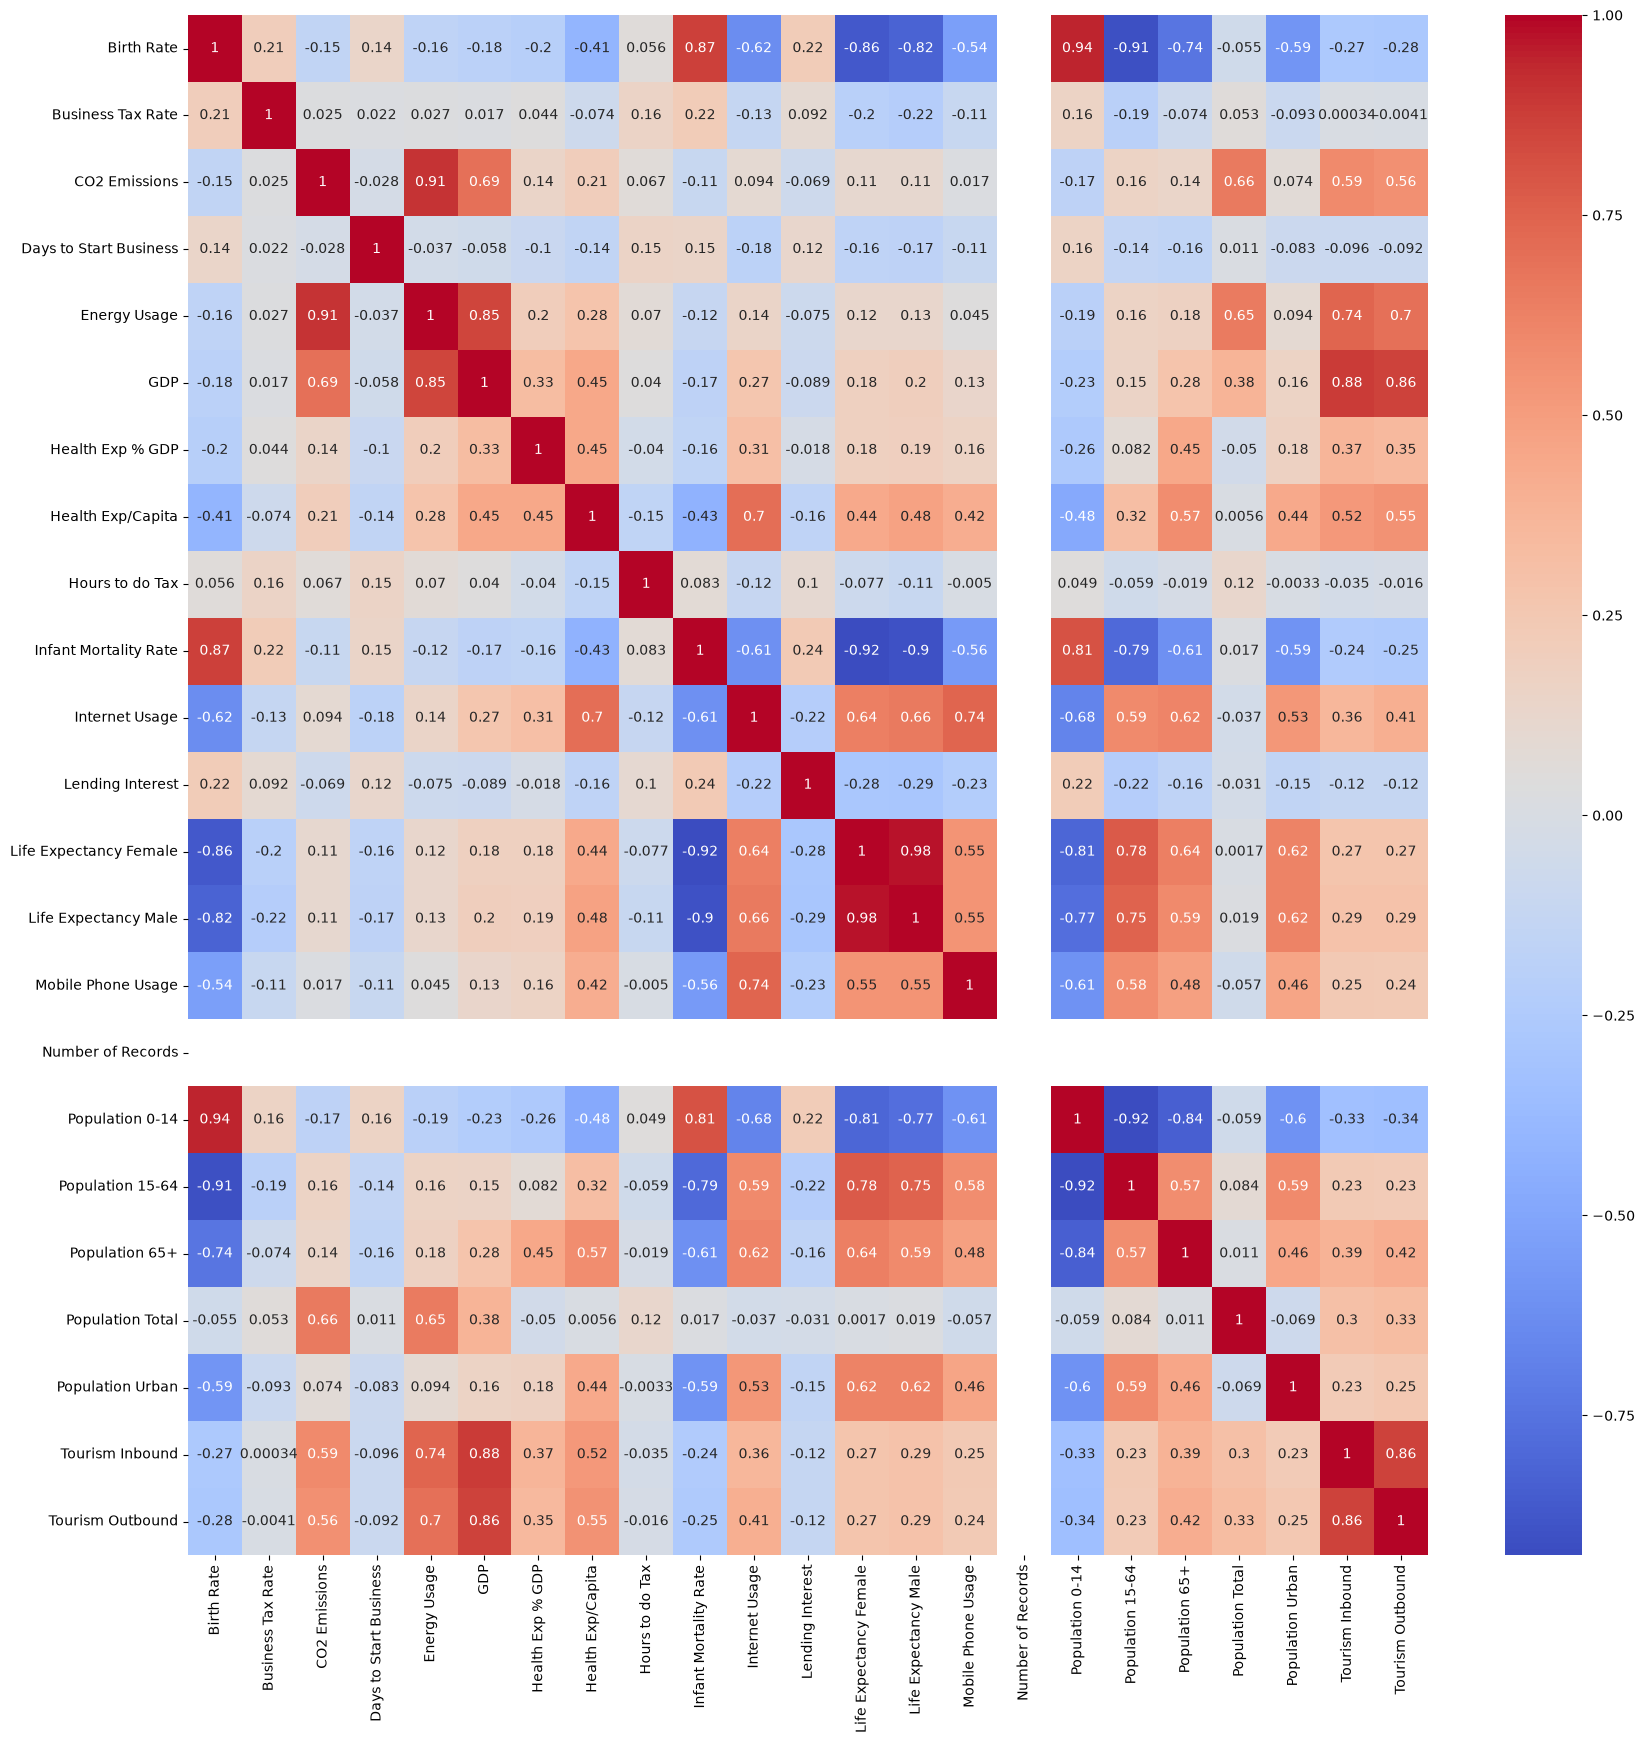

In [27]:
plt.figure(figsize = (20,20))
sns.heatmap(df[num_cols].corr(),annot = True,cmap = 'coolwarm')
plt.show()

In [28]:
df = df.drop('Number of Records',axis = 1)

In [29]:
df.shape

(2704, 23)

In [30]:
df = df.drop('Country',axis = 1)

In [31]:
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(col,':',len(outliers))

Birth Rate : 0
Business Tax Rate : 1130
CO2 Emissions : 387
Days to Start Business : 340
Energy Usage : 424
GDP : 414
Health Exp % GDP : 58
Health Exp/Capita : 412
Hours to do Tax : 980
Infant Mortality Rate : 49
Internet Usage : 0
Lending Interest : 245
Life Expectancy Female : 14
Life Expectancy Male : 11
Mobile Phone Usage : 11
Population 0-14 : 0
Population 15-64 : 9
Population 65+ : 5
Population Total : 318
Population Urban : 0
Tourism Inbound : 409
Tourism Outbound : 461


In [32]:
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    df[col] = df[col].clip(lower = lower_bound,upper = upper_bound)

In [33]:
df.describe()

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
count,2704.000000,2704.000000,2704.000000,2704.000000,2704.00000,2.704000e+03,2704.00000,2704.000000,2704.000000,2704.000000,...,2704.000000,2704.000000,2704.000000,2704.000000,2704.000000,2704.000000,2.704000e+03,2704.000000,2.704000e+03,2.704000e+03
mean,0.022595,41.166568,27300.822670,28.139978,18268.08358,5.968253e+10,0.06303,393.259430,240.672707,0.031404,...,71.363536,66.599112,0.572319,0.302762,0.624969,0.071684,1.357105e+07,0.562924,1.825707e+09,1.191360e+09
std,0.011100,2.571279,36536.837773,14.167603,14774.93527,8.148197e+10,0.02214,446.539198,34.267822,0.028215,...,10.438511,9.141010,0.456606,0.102152,0.066771,0.047735,1.664077e+07,0.244712,2.285833e+09,1.488580e+09
min,0.007000,37.550000,7.000000,1.000000,8.00000,6.310127e+07,0.00800,2.000000,189.750000,0.002000,...,44.000000,43.000000,0.000000,0.118000,0.474000,0.003000,1.887600e+04,0.082000,7.000000e+05,2.000000e+05
25%,0.013000,40.400000,2237.000000,20.000000,7851.75000,4.113748e+09,0.04800,58.000000,229.500000,0.010000,...,65.000000,61.000000,0.200000,0.210000,0.565000,0.034000,8.783360e+05,0.357750,1.860000e+08,1.470000e+08
50%,0.020000,41.000000,8529.000000,26.000000,14338.00000,1.507975e+10,0.06100,193.000000,239.000000,0.020000,...,75.000000,69.000000,0.500000,0.299500,0.642500,0.052000,5.800324e+06,0.560000,6.885000e+08,4.560000e+08
75%,0.030000,42.300000,42562.000000,34.250000,23476.50000,9.101825e+10,0.07600,551.250000,256.000000,0.049000,...,79.000000,73.000000,0.900000,0.395000,0.673000,0.105000,2.014089e+07,0.763000,2.648000e+09,1.711500e+09
max,0.053000,45.150000,103049.500000,55.625000,46913.62500,2.213750e+11,0.11800,1291.125000,295.750000,0.107500,...,87.000000,88.000000,1.950000,0.500000,0.835000,0.211500,4.903473e+07,1.000000,6.341000e+09,4.058250e+09


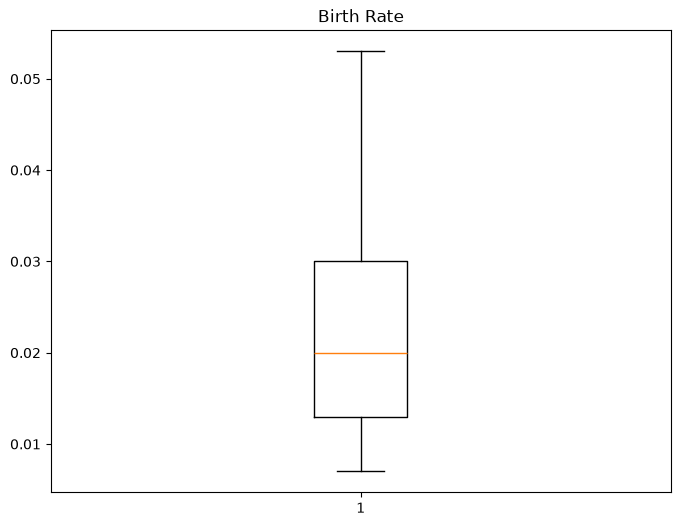

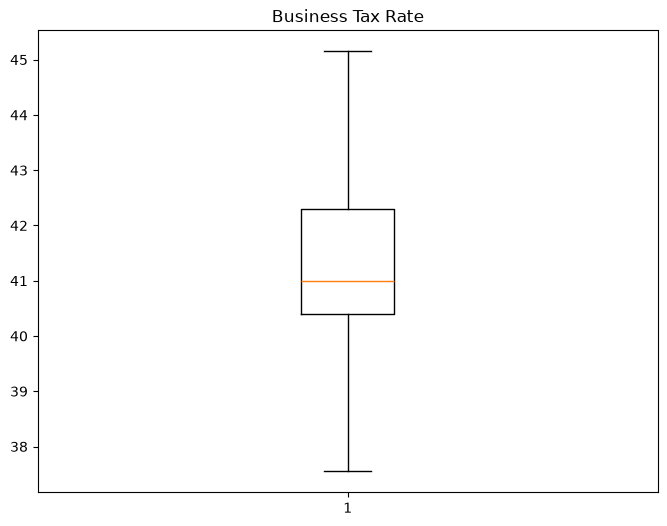

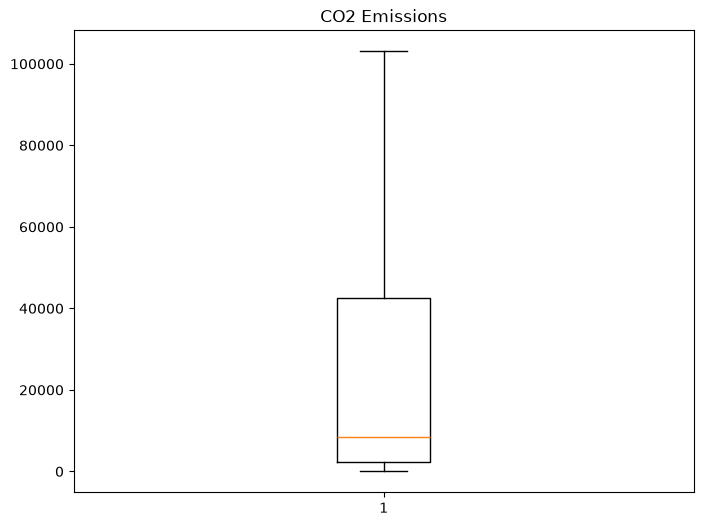

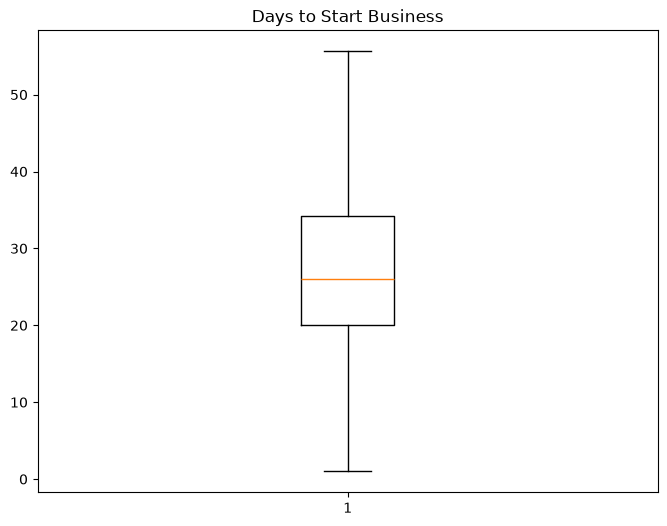

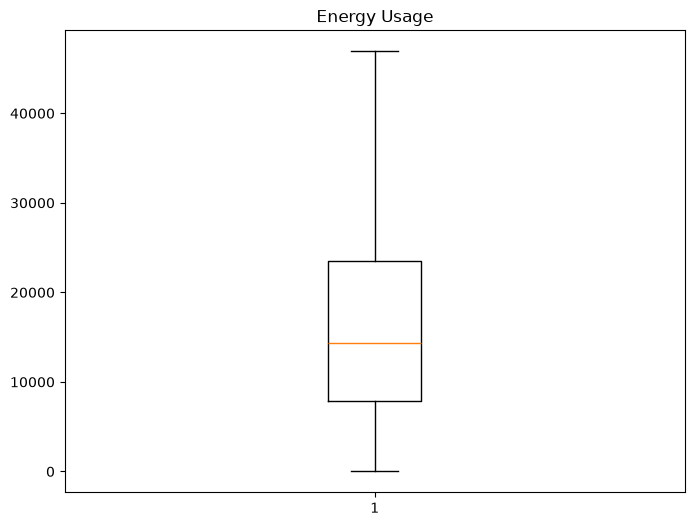

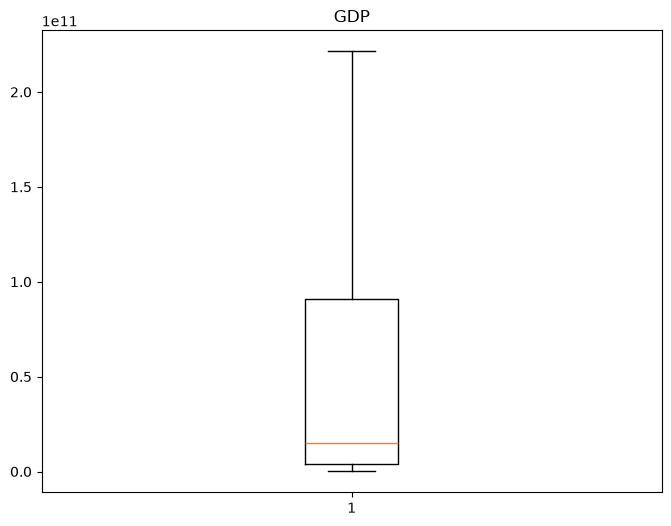

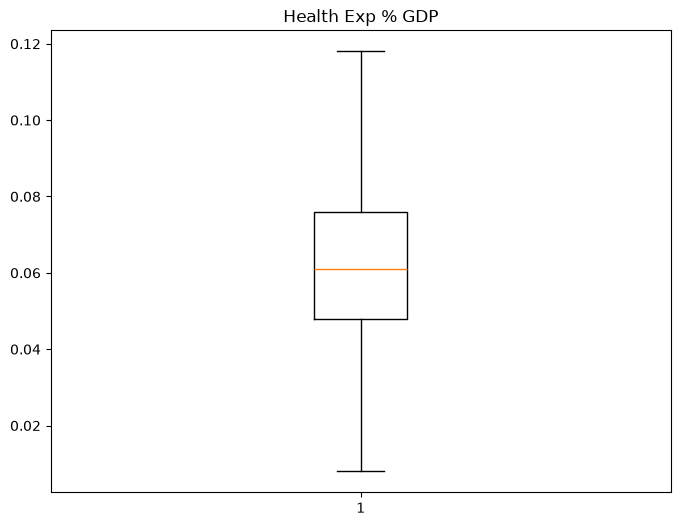

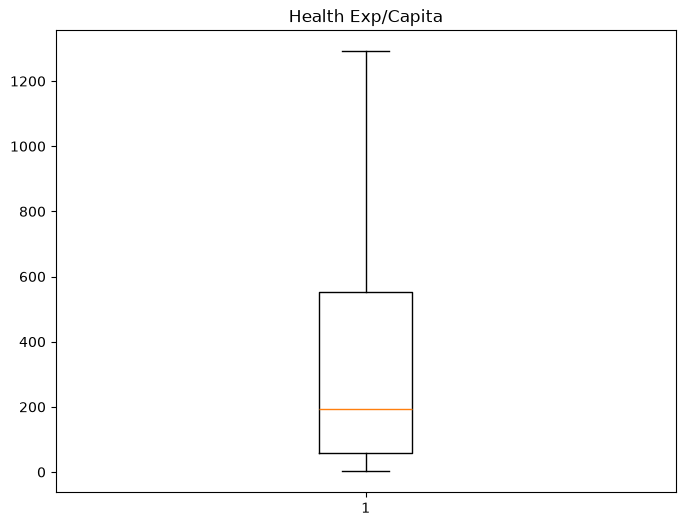

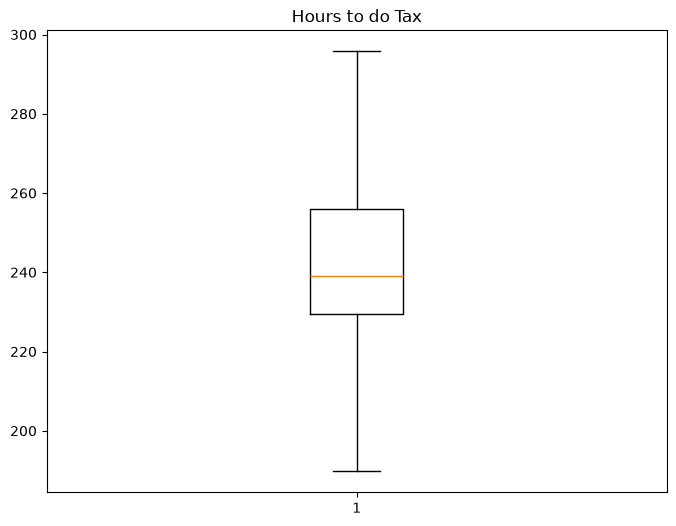

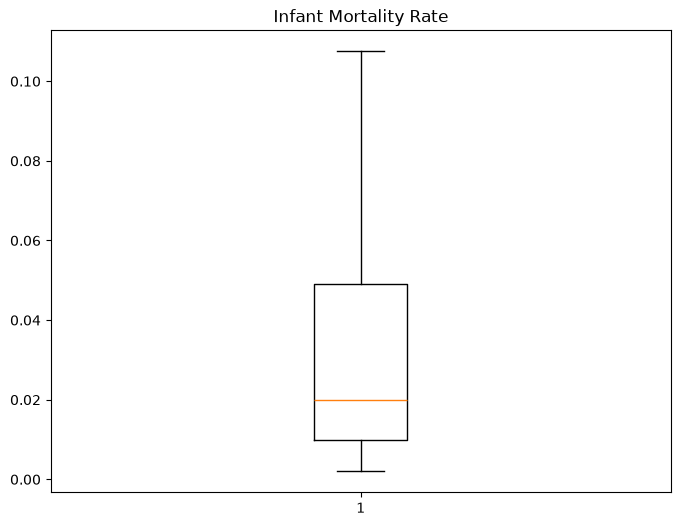

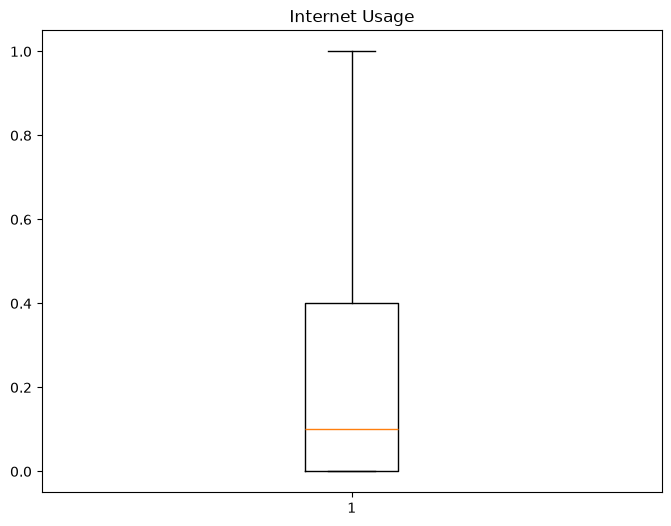

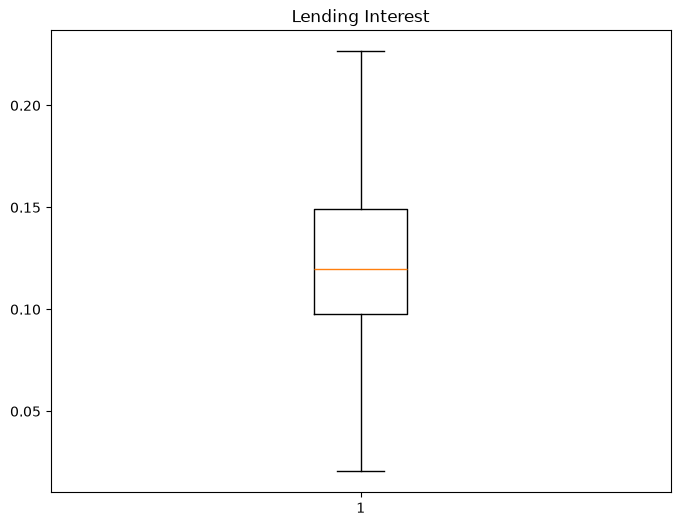

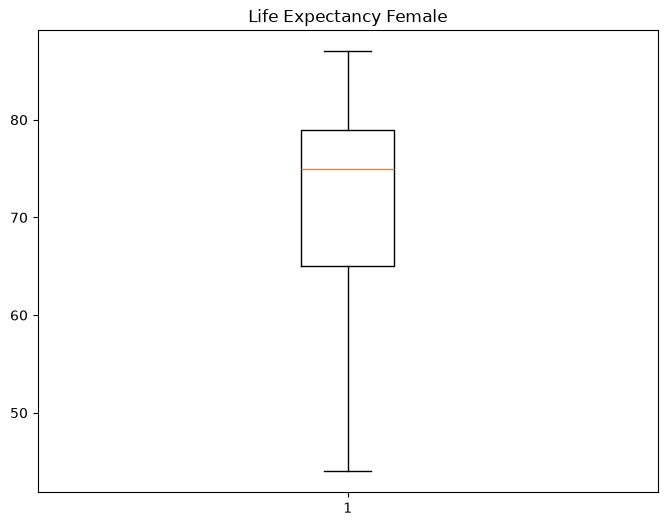

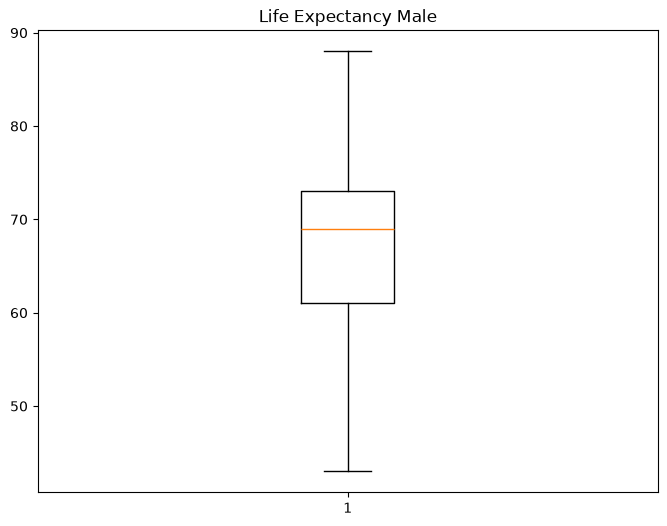

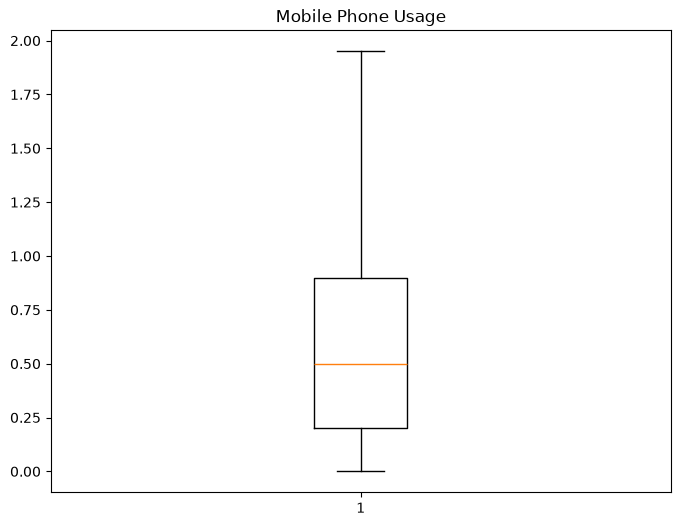

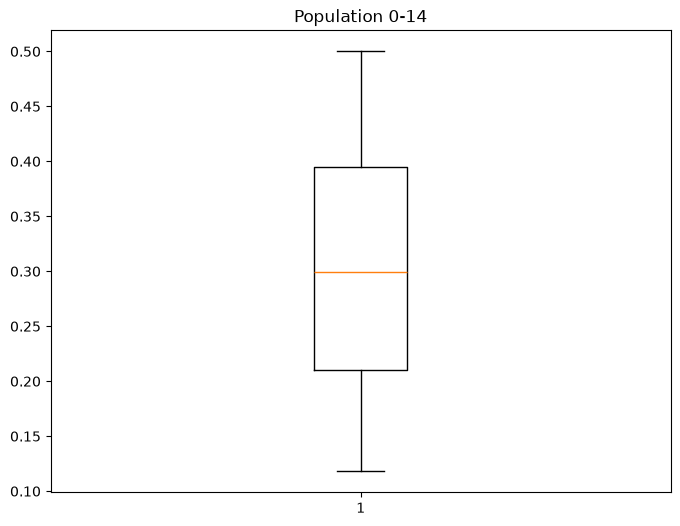

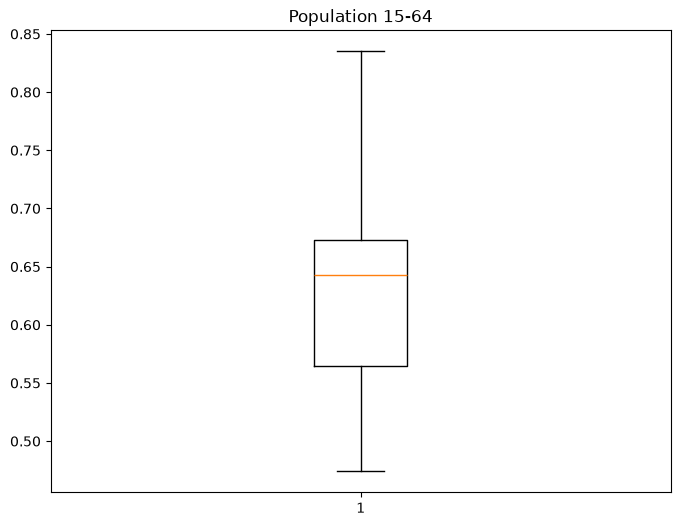

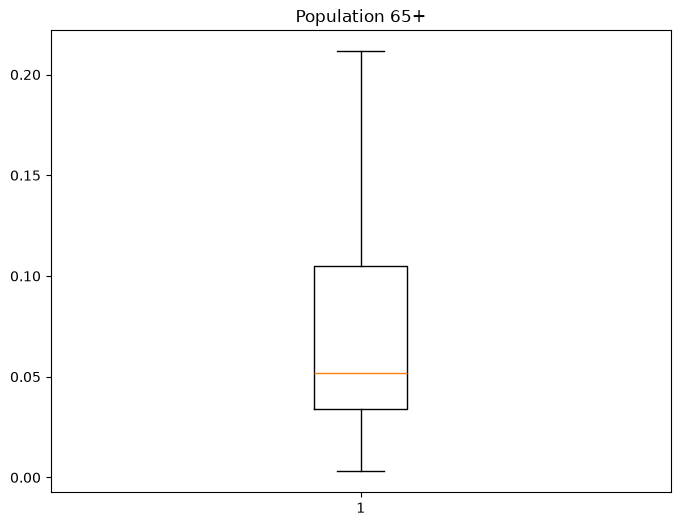

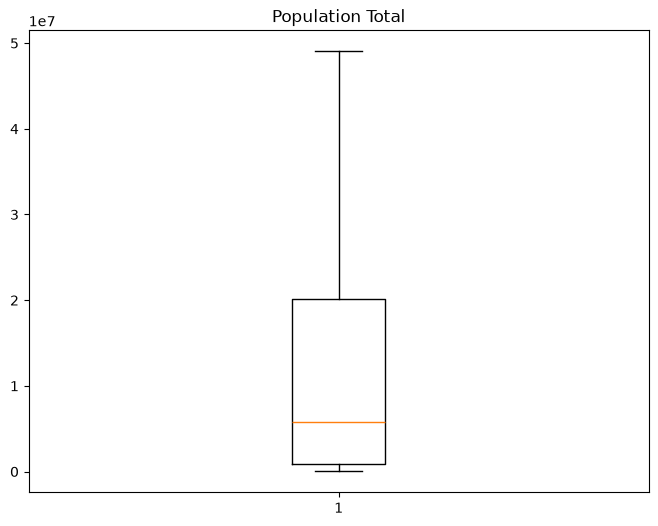

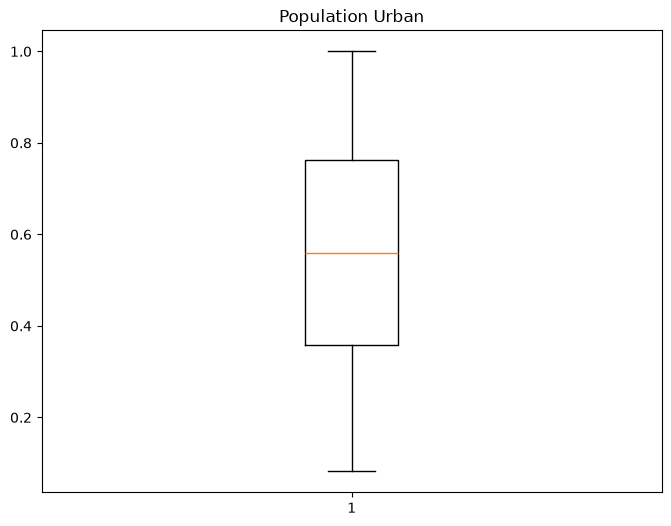

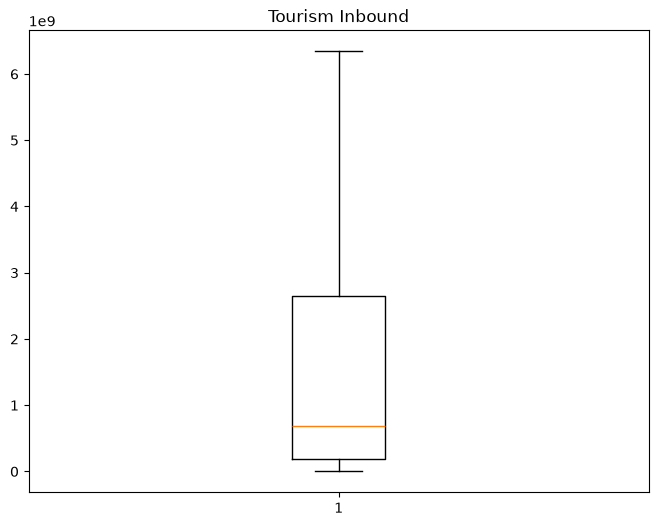

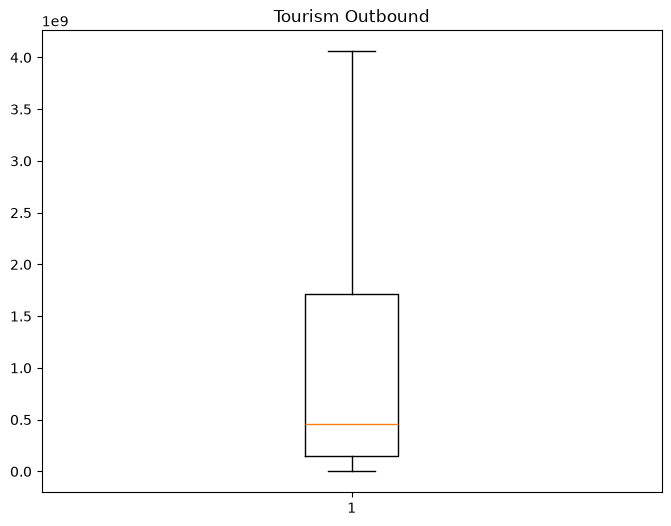

In [34]:
for col in df.columns:
    plt.figure(figsize = (8,6))
    plt.boxplot(df[col])
    plt.title(col)
    plt.show()

In [35]:
from sklearn.preprocessing import StandardScaler

In [36]:
SS = StandardScaler()

x_scaled = SS.fit_transform(df)

In [37]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans,DBSCAN,AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [38]:
pca = PCA(n_components = 0.95)

x_pca = pca.fit_transform(x_scaled)

print('Original Shape:',x_scaled.shape)
print('PCA Shape:',x_pca.shape)

print('Explained variance:',round(pca.explained_variance_ratio_.sum(),4))

Original Shape: (2704, 22)
PCA Shape: (2704, 13)
Explained variance: 0.9612


In [39]:
# ELBOW Method - SCALED DATA

inertia_scaled = []
inertia_pca = []

for k in range(2,11):
    km_scaled = KMeans(n_clusters = k,random_state = 42,n_init = 10)
    km_scaled.fit(x_scaled)
    inertia_scaled.append(km_scaled.inertia_)

# ELBOW METHOD - PCA DATA

for k in range(2,11):
    km_pca = KMeans(n_clusters = k,random_state = 42,n_init = 10)
    km_pca.fit(x_pca)
    inertia_pca.append(km_pca.inertia_)

In [40]:
# SILHOUETTE SCORE - SCALED AND PCA

sil_scaled = []
sil_pca = []

for k in range(2,11):
    
    # Scaled
    
    km_scaled = KMeans(n_clusters = k,random_state = 42,n_init = 10)
    labeled_scaled = km_scaled.fit_predict(x_scaled)
    scaled_score = silhouette_score(x_scaled,labeled_scaled)
    sil_scaled.append(scaled_score)

    # PCA

    km_pca = KMeans(n_clusters = k,random_state = 42,n_init = 10)
    labels_pca = km_pca.fit_predict(x_pca)
    score_pca = silhouette_score(x_pca,labels_pca)
    sil_pca.append(score_pca)

In [41]:
print("\nK VALUE COMPARISON")
print("-" * 55)

for i, k in enumerate(range(2,11)):

    print(
        f"K={k} | "
        f"Scaled Silhouette={sil_scaled[i]:.4f} | "
        f"PCA Silhouette={sil_pca[i]:.4f}"
    )


best_k_scaled = list(range(2,11))[
    np.argmax(sil_scaled)
]

best_k_pca = list(range(2,11))[
    np.argmax(sil_pca)
]

print("\nBest K - Scaled Data:", best_k_scaled)
print("Best K - PCA Data:", best_k_pca)


K VALUE COMPARISON
-------------------------------------------------------
K=2 | Scaled Silhouette=0.2556 | PCA Silhouette=0.2661
K=3 | Scaled Silhouette=0.2568 | PCA Silhouette=0.2698
K=4 | Scaled Silhouette=0.2666 | PCA Silhouette=0.2807
K=5 | Scaled Silhouette=0.1970 | PCA Silhouette=0.2090
K=6 | Scaled Silhouette=0.1625 | PCA Silhouette=0.1743
K=7 | Scaled Silhouette=0.1592 | PCA Silhouette=0.1624
K=8 | Scaled Silhouette=0.1549 | PCA Silhouette=0.1593
K=9 | Scaled Silhouette=0.1476 | PCA Silhouette=0.1516
K=10 | Scaled Silhouette=0.1426 | PCA Silhouette=0.1532

Best K - Scaled Data: 4
Best K - PCA Data: 4


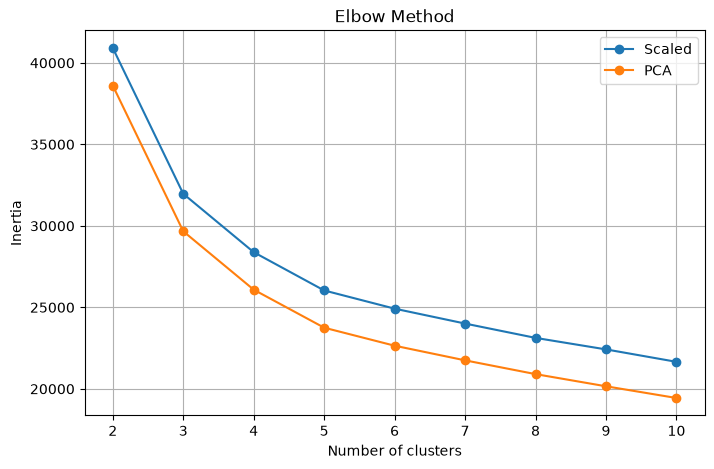

In [42]:
plt.figure(figsize = (8,5))
plt.plot(range(2,11),inertia_scaled,marker = 'o',label = 'Scaled')
plt.plot(range(2,11),inertia_pca,marker = 'o',label = 'PCA')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.legend()
plt.grid(True)
plt.show()

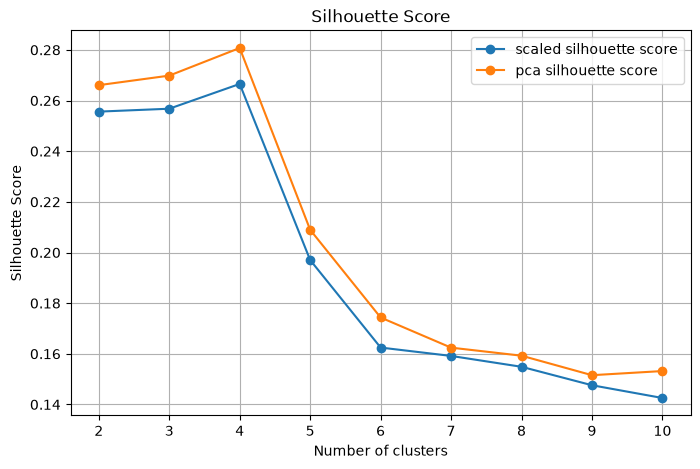

In [43]:
plt.figure(figsize = (8,5))
plt.plot(range(2,11),sil_scaled,marker = 'o',label = 'scaled silhouette score')
plt.plot(range(2,11),sil_pca,marker = 'o',label = 'pca silhouette score')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.legend()
plt.grid(True)
plt.show()

In [44]:
# Final KMeans - Scaled Data

kmeans_scaled = KMeans(n_clusters = 4,random_state = 42,n_init = 10)
labels_kmeans_scaled = kmeans_scaled.fit_predict(x_scaled)
final_sil_scaled = silhouette_score(x_scaled,labels_kmeans_scaled)

print('Scaled Silhouette Score:',final_sil_scaled)

# Final KMeans - PCA Data

kmeans_pca = KMeans(n_clusters = 4,random_state = 42,n_init = 10)
labels_kmeans_pca = kmeans_pca.fit_predict(x_pca)
final_sil_pca = silhouette_score(x_pca,labels_kmeans_pca)

print('PCA Silhouette Score:',final_sil_pca)

Scaled Silhouette Score: 0.2665509402368834
PCA Silhouette Score: 0.2807447829602635


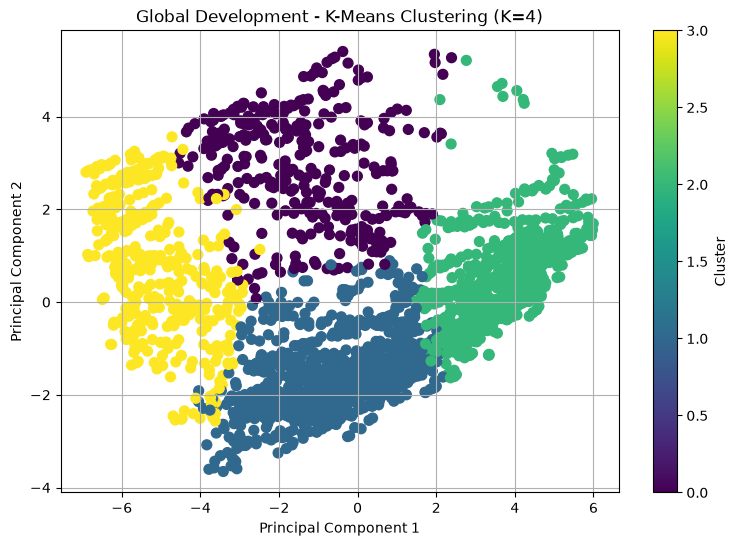

In [45]:
plt.figure(figsize=(9, 6))

plt.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=labels_kmeans_pca,
    cmap='viridis',
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Global Development - K-Means Clustering (K=4)")

plt.colorbar(label="Cluster")

plt.grid(True)
plt.show()

In [46]:
# Hierarchical - Scaled Data


hier_scaled = AgglomerativeClustering(
    n_clusters = 4,
    linkage='ward'
)

labels_hier_scaled = hier_scaled.fit_predict(x_scaled)

sil_hier_scaled = silhouette_score(x_scaled,labels_hier_scaled)


# Hierarchical - PCA Data

hier_pca = AgglomerativeClustering(
    n_clusters = 4,
    linkage = 'ward'
)

labels_hier_pca = hier_pca.fit_predict(x_pca)

sil_hier_pca = silhouette_score(x_pca,labels_hier_pca)


print('Silhouette Score Scaled:',sil_hier_scaled)
print('Silhouette Score PCA:',sil_hier_pca)

Silhouette Score Scaled: 0.15694445362718282
Silhouette Score PCA: 0.24942337694210454


In [47]:
# DBSCAN - Scaled Data

dbscan_scaled = DBSCAN(
    eps = 1.5,
    min_samples = 5
)

labels_dbscan_scaled = dbscan_scaled.fit_predict(x_scaled)

mask_scaled = labels_dbscan_scaled != -1

n_clusters_dbscan_scaled = len(set(labels_dbscan_scaled[mask_scaled]))

noise_scaled = np.sum(labels_dbscan_scaled == -1)

if n_clusters_dbscan_scaled >= 2:
    sil_dbscan_scaled = silhouette_score(
        x_scaled[mask_scaled],
        labels_dbscan_scaled[mask_scaled]
    )
else:
    sil_dbscan_scaled = np.nan


# DBSCAN - PCA DATA


dbscan_pca = DBSCAN(
    eps=1.5,
    min_samples=5
)

labels_dbscan_pca = dbscan_pca.fit_predict(x_pca)

mask_pca = labels_dbscan_pca != -1

n_clusters_db_pca = len(set(labels_dbscan_pca[mask_pca]))

noise_pca = np.sum(labels_dbscan_pca == -1)

if n_clusters_db_pca >= 2:

    sil_dbscan_pca = silhouette_score(
        x_pca[mask_pca],
        labels_dbscan_pca[mask_pca]
    )
else:
    sil_dbscan_pca = np.nan



print('Silhouette Score Scaled:',sil_dbscan_scaled)
print('Silhouette Score PCA:',sil_dbscan_pca)

Silhouette Score Scaled: 0.18173631640859947
Silhouette Score PCA: 0.07001825167019289


In [48]:
# Silhouette Score Comparision

comparison = pd.DataFrame({

    'Algorithm': [
        'K-Means',
        'K-Means',
        'Hierarchical',
        'Hierarchical',
        'DBSCAN',
        'DBSCAN'
    ],

    'Data': [
        'Scaled - 22 Features',
        'PCA - 13 Components',
        'Scaled - 22 Features',
        'PCA - 13 Components',
        'Scaled - 22 Features',
        'PCA - 13 Components'
    ],

    'Silhouette Score': [
        final_sil_scaled,
        final_sil_pca,
        sil_hier_scaled,
        sil_hier_pca,
        sil_dbscan_scaled,
        sil_dbscan_pca
    ]
})

In [49]:
comparison

,Algorithm,Data,Silhouette Score
0,K-Means,Scaled - 22 Features,0.266551
1,K-Means,PCA - 13 Components,0.280745
2,Hierarchical,Scaled - 22 Features,0.156944
3,Hierarchical,PCA - 13 Components,0.249423
4,DBSCAN,Scaled - 22 Features,0.181736
5,DBSCAN,PCA - 13 Components,0.070018


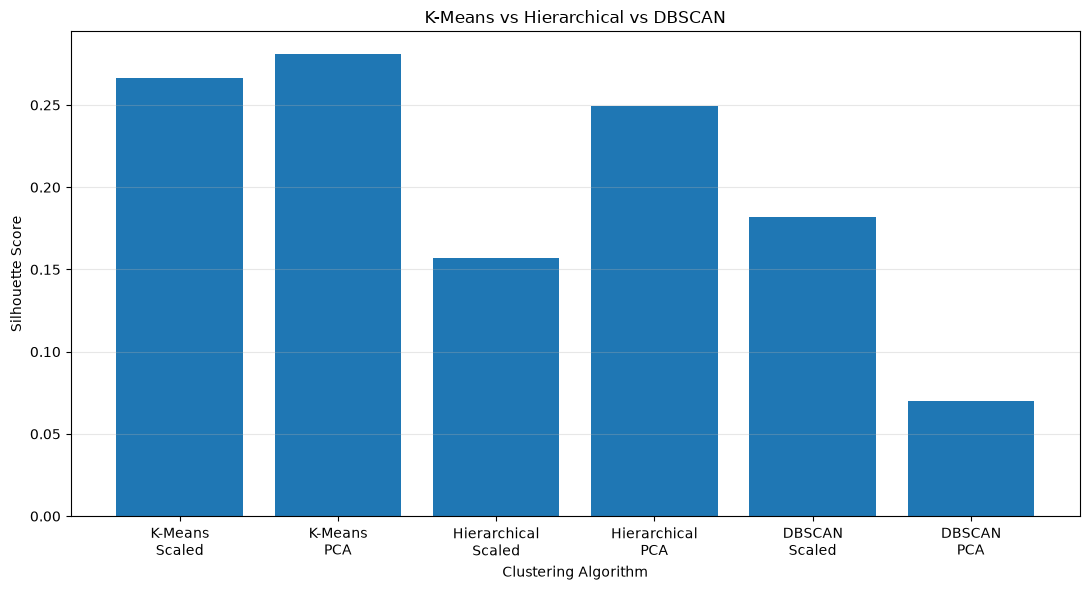

In [50]:
plt.figure(figsize=(11, 6))

labels = [
    'K-Means\nScaled',
    'K-Means\nPCA',
    'Hierarchical\nScaled',
    'Hierarchical\nPCA',
    'DBSCAN\nScaled',
    'DBSCAN\nPCA'
]

scores = comparison[
    'Silhouette Score'
].values

plt.bar(
    labels,
    scores
)

plt.xlabel("Clustering Algorithm")
plt.ylabel("Silhouette Score")
plt.title(
    "K-Means vs Hierarchical vs DBSCAN"
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [51]:
# Final K-Means Model

kmeans_final = KMeans(
    n_clusters = 4,
    random_state = 42,
    n_init = 10
)

labels_final = kmeans_final.fit_predict(x_pca)

df['Cluster'] = labels_final

In [52]:
# Cluster Profiling

num_cols = df.select_dtypes(include = ['int64','float64']).columns

cluster_profile = df.groupby('Cluster')[num_cols].mean()

cluster_profile

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.019738,41.661012,87290.991071,30.498884,41551.023438,1.566487e+11,0.051113,235.669643,258.043155,0.026732,...,72.979167,67.288690,0.524405,0.285018,0.651536,0.063435,4.027112e+07,0.588833,3.590504e+09,2.652295e+09
1,0.017214,40.794210,12577.234291,26.655072,10794.943671,1.841833e+10,0.062298,395.382518,236.132181,0.016860,...,76.549372,70.767504,0.670961,0.265572,0.656928,0.076286,3.728011e+06,0.632104,1.007518e+09,5.107993e+08
2,0.036333,41.400719,6032.698204,34.195659,11044.258683,1.000857e+10,0.057984,68.376048,245.795210,0.065755,...,58.507784,55.819162,0.221796,0.423186,0.543832,0.032971,1.248821e+07,0.346538,2.917697e+08,2.460952e+08
3,0.011819,41.293437,60723.889021,18.128282,33862.126193,1.906263e+11,0.084587,1161.428103,228.606802,0.005365,...,81.899761,76.446301,1.047017,0.175885,0.680387,0.143211,2.048771e+07,0.789442,5.642720e+09,3.712998e+09


In [53]:
cluster_median = df.groupby('Cluster')[num_cols].median()

cluster_median

,Birth Rate,Business Tax Rate,CO2 Emissions,Days to Start Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,Hours to do Tax,Infant Mortality Rate,...,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.020,41.0,103049.5,26.0,46913.625,1.721412e+11,0.051,155.500,239.0,0.0215,...,74.0,68.0,0.5,0.297,0.650,0.052,4.903473e+07,0.6155,3.423500e+09,3.028000e+09
1,0.017,41.0,8529.0,26.0,14338.000,1.380380e+10,0.061,220.500,239.0,0.0170,...,76.0,70.0,0.6,0.283,0.654,0.062,1.109862e+06,0.6340,6.885000e+08,4.560000e+08
2,0.037,41.0,2321.0,26.0,14338.000,5.323147e+09,0.056,37.000,239.0,0.0640,...,59.0,56.0,0.1,0.426,0.543,0.031,8.624280e+06,0.3290,1.230000e+08,1.390000e+08
3,0.011,41.0,57917.0,18.0,35031.000,2.213750e+11,0.086,1291.125,239.0,0.0040,...,82.0,77.0,1.1,0.171,0.673,0.151,1.038460e+07,0.7990,6.341000e+09,4.058250e+09


In [54]:
cluster_counts = df['Cluster'].value_counts().sort_index()

cluster_counts

Cluster
0     336
1    1114
2     835
3     419
Name: count, dtype: int64

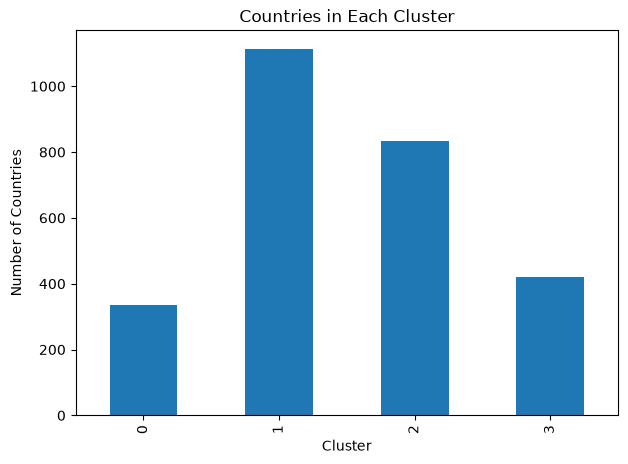

In [55]:
cluster_counts.plot(
    kind='bar',
    figsize=(7, 5)
)

plt.xlabel("Cluster")
plt.ylabel("Number of Countries")
plt.title("Countries in Each Cluster")

plt.show()

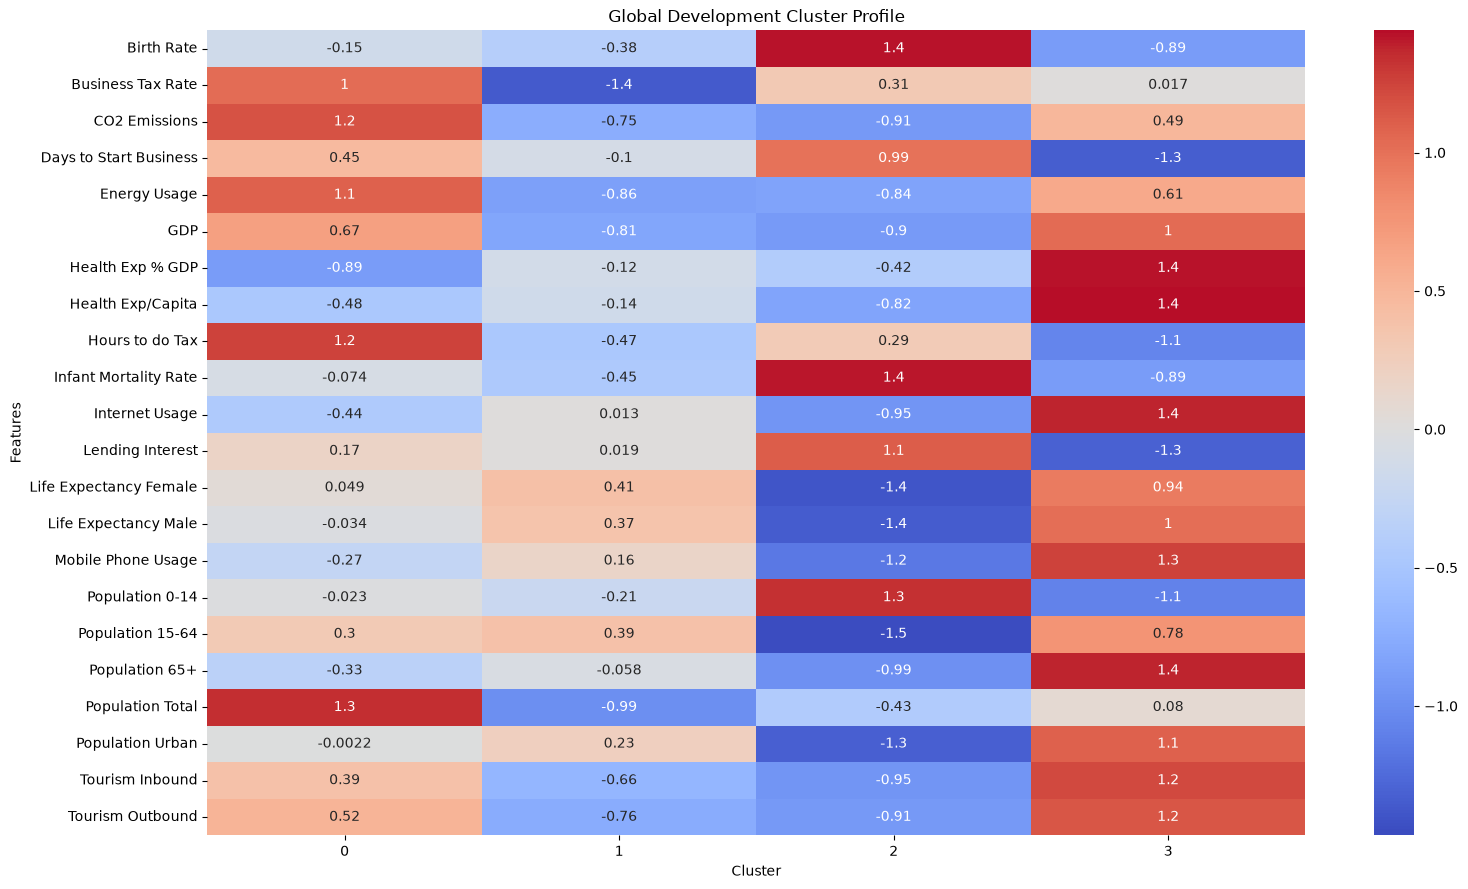

In [56]:
# Cluster Profile Heatmap

profile = df.groupby(
    'Cluster'
)[num_cols].mean()

profile_z = (
    profile - profile.mean()
) / profile.std()

plt.figure(figsize=(16, 9))

sns.heatmap(
    profile_z.T,
    annot = True,
    cmap='coolwarm',
    center=0
)

plt.title(
    "Global Development Cluster Profile"
)

plt.xlabel("Cluster")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [57]:
# Cluster Interpretation


for cluster in profile_z.index:

    print("\n" + "=" * 60)
    print(f"CLUSTER {cluster}")
    print("=" * 60)

    values = profile_z.loc[cluster].sort_values()

    print("\nLowest 5 Features:")
    print(
        values.head(5).round(2)
    )

    print("\nHighest 5 Features:")
    print(
        values.tail(5)
        .sort_values(ascending=False)
        .round(2)
    )


CLUSTER 0

Lowest 5 Features:
Health Exp % GDP     -0.89
Health Exp/Capita    -0.48
Internet Usage       -0.44
Population 65+       -0.33
Mobile Phone Usage   -0.27
Name: 0, dtype: float64

Highest 5 Features:
Population Total     1.35
Hours to do Tax      1.25
CO2 Emissions        1.17
Energy Usage         1.09
Business Tax Rate    1.03
Name: 0, dtype: float64

CLUSTER 1

Lowest 5 Features:
Business Tax Rate   -1.36
Population Total    -0.99
Energy Usage        -0.86
GDP                 -0.81
Tourism Outbound    -0.76
Name: 1, dtype: float64

Highest 5 Features:
Life Expectancy Female    0.41
Population 15-64          0.39
Life Expectancy Male      0.37
Population Urban          0.23
Mobile Phone Usage        0.16
Name: 1, dtype: float64

CLUSTER 2

Lowest 5 Features:
Population 15-64         -1.47
Life Expectancy Female   -1.40
Life Expectancy Male     -1.35
Population Urban         -1.32
Mobile Phone Usage       -1.15
Name: 2, dtype: float64

Highest 5 Features:
Birth Rate         

In [58]:
feature_names = num_cols.copy()

print('Number of features:',len(feature_names))
print(feature_names)

Number of features: 22
Index(['Birth Rate', 'Business Tax Rate', 'CO2 Emissions',
       'Days to Start Business', 'Energy Usage', 'GDP', 'Health Exp % GDP',
       'Health Exp/Capita', 'Hours to do Tax', 'Infant Mortality Rate',
       'Internet Usage', 'Lending Interest', 'Life Expectancy Female',
       'Life Expectancy Male', 'Mobile Phone Usage', 'Population 0-14',
       'Population 15-64', 'Population 65+', 'Population Total',
       'Population Urban', 'Tourism Inbound', 'Tourism Outbound'],
      dtype='str')


In [59]:
import joblib

# Save the preprocessing and final model

joblib.dump(SS,'scaler.pkl')
joblib.dump(pca,'pca.pkl')
joblib.dump(kmeans_pca,'kmeans_model.pkl')
joblib.dump(feature_names,'feature_names.pkl')


print("Best model pipeline saved successfully!")
print("Scaler       : scaler.pkl")
print("PCA          : pca.pkl")
print("K-Means      : kmeans_model.pkl")
print("Features     : feature_names.pkl")
print("Features     :", len(feature_names))
print("PCA Components:", pca.n_components_)
print("K-Means K    :", kmeans_pca.n_clusters)

Best model pipeline saved successfully!
Scaler       : scaler.pkl
PCA          : pca.pkl
K-Means      : kmeans_model.pkl
Features     : feature_names.pkl
Features     : 22
PCA Components: 13
K-Means K    : 4


In [60]:
# Load saved files
scaler = joblib.load('scaler.pkl')
pca_model = joblib.load('pca.pkl')
kmeans_model = joblib.load('kmeans_model.pkl')
feature_names = joblib.load('feature_names.pkl')

# Check saved components
print("Number of input features :", len(feature_names))
print("PCA components           :", pca_model.n_components_)
print("Explained variance       :", pca_model.explained_variance_ratio_.sum())
print("Number of clusters       :", kmeans_model.n_clusters)

# Check model pipeline with existing data
X_input = df[feature_names]

X_scaled_test = scaler.transform(X_input)
X_pca_test = pca_model.transform(X_scaled_test)
predictions = kmeans_model.predict(X_pca_test)

print("\nPCA data shape :", X_pca_test.shape)
print("Prediction shape:", predictions.shape)
print("Clusters found:", np.unique(predictions))

Number of input features : 22
PCA components           : 13
Explained variance       : 0.9611931885641015
Number of clusters       : 4

PCA data shape : (2704, 13)
Prediction shape: (2704,)
Clusters found: [0 1 2 3]


In [61]:
# Enter values manually
values = [
    20,       # Birth Rate
    30,       # Business Tax Rate
    500,      # CO2 Emissions
    20,       # Days to Start Business
    2000,     # Energy Usage
    50000,    # GDP
    8,        # Health Exp % GDP
    3000,     # Health Exp/Capita
    200,      # Hours to do Tax
    15,       # Infant Mortality Rate
    70,       # Internet Usage
    8,        # Lending Interest
    75,       # Life Expectancy Female
    70,       # Life Expectancy Male
    100,      # Mobile Phone Usage
    25,       # Population 0-14
    65,       # Population 15-64
    10,       # Population 65+
    10000000, # Population Total
    60,       # Population Urban
    5000,     # Tourism Inbound
    4000      # Tourism Outbound
]

# Create input DataFrame
input_data = pd.DataFrame(
    [values],
    columns=feature_names
)

# Scaling
scaled_data = scaler.transform(input_data)

# PCA transformation
pca_data = pca_model.transform(scaled_data)

# Prediction
cluster = kmeans_model.predict(pca_data)[0]

print("===================================")
print("       MANUAL TESTING RESULT")
print("===================================")

print("Input Features :", len(values))
print("PCA Components :", pca_data.shape[1])
print("Predicted Cluster:", cluster)

       MANUAL TESTING RESULT
Input Features : 22
PCA Components : 13
Predicted Cluster: 2
